In [33]:
!pip3 install wordcloud


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


# Imports principaux des Librairies nécessaire au travail

In [34]:
import requests
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

import nltk
import spacy
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# Téléchargement des ressources NLTK

NLTK permet de nettoyer, d'analyser et de préparer du texte pour que des modèles de Machine Learning ou d'IA puissent le comprendre. Il est très utilisé pour la recherche

In [35]:
import nltk

nltk.download('punkt')       # Tokeniseur de phrases et mots
nltk.download('punkt_tab')   # Ressource complémentaire (versions récentes de NLTK)
nltk.download('stopwords')   # Listes de mots vides (français, anglais...)
nltk.download('wordnet')     # Base lexicale pour la lemmatisation
nltk.download('omw-1.4')    # Open Multilingual Wordnet (multilingue)


[nltk_data] Downloading package punkt to ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to ~/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

# Téléchargement du modèle SpaCy et verification

In [36]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "spacy", "download", "fr_core_news_sm"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 6.6 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['python', '-m', 'spacy', 'download', 'fr_core_news_sm'], returncode=0)

In [37]:
import spacy
nlp = spacy.load('fr_core_news_sm')
print('Modèle SpaCy chargé avec succès !')


Modèle SpaCy chargé avec succès !


# 2.1  Téléchargement du roman

In [38]:
import requests

URL = 'https://www.gutenberg.org/files/17989/17989-0.txt'

# Téléchargement
response = requests.get(URL)
response.encoding = 'utf-8'
raw_text = response.text

print(f'Téléchargement terminé.')
print(f'Taille brute : {len(raw_text):,} caractères')
print(f'Aperçu :\n{raw_text[:300]}')


Téléchargement terminé.
Taille brute : 727,600 caractères
Aperçu :
*** START OF THE PROJECT GUTENBERG EBOOK 17989 ***




LE COMTE DE MONTE-CRISTO

Alexandre Dumas

Tome I (1845-1846)




Table des matières


Alexandre Dumas
I  Marseille.--L'arrivée.
II  Le père et le fils.
III  Les Catalans.
IV  Complot.
V  Le repas des fiançailles.
VI  Le substitut du procureur d


# 2.2  Extraction du contenu (sans les métadonnées Gutenberg)

In [39]:
# Le fichier Gutenberg contient un en-tête et un pied de page
# On extrait uniquement le roman
DEBUT = '*** START OF THE PROJECT GUTENBERG EBOOK 17989 ***'
FIN   = '*** END OF THE PROJECT GUTENBERG EBOOK 17989 ***'

roman = raw_text.split(DEBUT)[1].split(FIN)[0]

print(f'Taille du roman (sans métadonnées) : {len(roman):,} caractères')
print(f'Nombre de lignes : {roman.count(chr(10)):,}')
print(f'Aperçu :\n{roman[:500]}')


Taille du roman (sans métadonnées) : 727,501 caractères
Nombre de lignes : 16,694
Aperçu :





LE COMTE DE MONTE-CRISTO

Alexandre Dumas

Tome I (1845-1846)




Table des matières


Alexandre Dumas
I  Marseille.--L'arrivée.
II  Le père et le fils.
III  Les Catalans.
IV  Complot.
V  Le repas des fiançailles.
VI  Le substitut du procureur du roi.
VII  L'interrogatoire.
VIII  Le château d'If.
IX  Le soir des fiançailles.
X  Le petit cabinet des Tuileries.
XI  L'Ogre de Corse.
XII  Le père et le fils.
XIII  Les Cent-Jours.
XIV  Le prisonnier furieux et le prisonnier fou.
XV  Le numéro 34


# Sauvegarde locale (optionnel)

In [40]:
# Sauvegarder le roman en local pour éviter de re-télécharger
with open('monte_cristo.txt', 'w', encoding='utf-8') as f:
    f.write(roman)

# Chargement depuis le fichier local :
# with open('monte_cristo.txt', encoding='utf-8') as f:
#     roman = f.read()


# ✏️  Travail demandé

### a)  Téléchargez le roman et affichez :

    - Le nombre total de caractères (len)

    - Le nombre total de lignes (count('\n'))

    - Les 500 premiers caractères

    - Les 200 derniers caractères (pour voir la fin du fichier Gutenberg)


In [41]:
#Le nombre total de caractères

print("Le nombre total de caractères est",len(roman))

#Le nombre total de lignes

print("Le nombre total de lignes est",roman.count('\n'))

#Les 500 premiers carecteres

print("\n",f'Aperçu du début :\n{roman[:500]}')

#Les 200 derniers caractères
# Les 200 derniers caractères
print(f'Fin du roman :\n{roman[-200:]}')

Le nombre total de caractères est 727501
Le nombre total de lignes est 16694

 Aperçu du début :





LE COMTE DE MONTE-CRISTO

Alexandre Dumas

Tome I (1845-1846)




Table des matières


Alexandre Dumas
I  Marseille.--L'arrivée.
II  Le père et le fils.
III  Les Catalans.
IV  Complot.
V  Le repas des fiançailles.
VI  Le substitut du procureur du roi.
VII  L'interrogatoire.
VIII  Le château d'If.
IX  Le soir des fiançailles.
X  Le petit cabinet des Tuileries.
XI  L'Ogre de Corse.
XII  Le père et le fils.
XIII  Les Cent-Jours.
XIV  Le prisonnier furieux et le prisonnier fou.
XV  Le numéro 34
Fin du roman :
donna sans réserve et finit
par retomber haletant, brûlé de fatigue, épuisé de volupté, sous les
baisers de ces maîtresses de marbre et sous les enchantements de ce rêve
inouï.

FIN DU TOME PREMIER





### b)  Comptez le nombre de mots en utilisant simplement .split()
    (estimation rapide, avant toute tokenisation avancée)


In [42]:
# Étape 1 : On découpe le texte en morceaux dès qu'il y a un espace
nombre_de_mots = len(roman.split())


print("Estimation rapide du nombre de mots :", nombre_de_mots)

Estimation rapide du nombre de mots : 121579


### c)  Combien de fois apparaît le nom 'Dantès' dans le roman ?
    Utilisez roman.lower().count('dantès')


In [43]:
# Compter les occurrences du nom Dantès (en minuscules pour ne rien rater)
nb_dantes = roman.lower().count('dantès')

print(f"Le nom 'Dantès' apparaît {nb_dantes} fois dans le roman.")

Le nom 'Dantès' apparaît 777 fois dans le roman.


### d)  Cherchez les 5 premières lignes contenant le mot 'vengeance'.

In [44]:
# 1. On extrait toutes les lignes qui contiennent 'vengeance'
lignes_vengeance = [l for l in roman.split('\n') if 'vengeance' in l.lower()]

# 2. On affiche uniquement les 5 premières grâce aux crochets [:5]
print("Les 5 premières lignes contenant le mot 'vengeance' :")
print("-" * 50)
for ligne in lignes_vengeance[:5]:
    print(ligne)

Les 5 premières lignes contenant le mot 'vengeance' :
--------------------------------------------------
que Fernand surtout était terrible dans sa vengeance.»
«À la bonne heure, continua Danglars; ainsi votre vengeance aurait le
menaçant et fort pour toutes les vengeances; alors il manifesta à M.
qui, pour lui aussi, était devenu messager d'une rude vengeance. Alors,
Il se disait que c'était la haine des hommes et non la vengeance de Dieu


### e)  Estimez le nombre de pages du roman (supposer 300 mots / page).

In [45]:
nombre_de_pages = nombre_de_mots // 300

print(f"Estimation du nombre de pages : {nombre_de_pages} pages")

Estimation du nombre de pages : 405 pages


In [46]:
# (Code de configuration du chemin sys.path à laisser au-dessus si nécessaire)
from chargement_corpus.load import LoadRoman

URL = 'https://www.gutenberg.org/files/17989/17989-0.txt'
DEBUT = '*** START OF THE PROJECT GUTENBERG EBOOK 17989 ***'
FIN   = '*** END OF THE PROJECT GUTENBERG EBOOK 17989 ***'

try:
    # 1. On récupère le brut
    texte_brut = LoadRoman.load_roman(URL)
    
    # 2. On parse pour avoir le roman propre
    roman_propre = LoadRoman.extraire_roman(texte_brut, DEBUT, FIN)
    
    print("Opérations réussies !")
    print(f"Aperçu du roman : \n{roman_propre[:200]}")
    
except (RuntimeError, ValueError) as e:
    print(f"Erreur : {e}")

Opérations réussies !
Aperçu du roman : 
LE COMTE DE MONTE-CRISTO

Alexandre Dumas

Tome I (1845-1846)




Table des matières


Alexandre Dumas
I  Marseille.--L'arrivée.
II  Le père et le fils.
III  Les Catalans.
IV  Complot.
V  Le repas des


# 3.1  Identification des éléments à nettoyer

In [47]:
# Observez le texte brut avant nettoyage
print(repr(roman[1000:1200]))   # repr() montre les caractères cachés (\n, \t...)

"ame de la Garde signala le\ntrois-mâts le _Pharaon_, venant de Smyrne, Trieste et Naples.\n\nComme d'habitude, un pilote côtier partit aussitôt du port, rasa le\nchâteau d'If, et alla aborder le navire en"


# 3.2  Fonction de nettoyage

In [48]:
import re

def clean_text(text):
    """Nettoie un texte pour une analyse NLP en français."""
    # 1. Mise en minuscules
    text = text.lower()
    # 2. Suppression des marqueurs d'italique Gutenberg (_mot_)
    text = re.sub(r'_([^_]+)_', r'\1', text)
    # 3. Remplacement des sauts de ligne et tabulations par des espaces
    text = re.sub(r'[\n\r\t]+', ' ', text)
    # 4. Suppression de la ponctuation et des caractères spéciaux
    #    On conserve les lettres françaises accentuées
    text = re.sub(r"[^a-zàâçéèêëîïôûùüÿñæœ' ]", ' ', text)
    # 5. Normalisation des apostrophes typographiques
    text = re.sub(r"[''`]", "'", text)
    # 6. Suppression des espaces multiples
    text = re.sub(r'\s+', ' ', text)
    # 7. Suppression des espaces en début et fin
    text = text.strip()
    return text

roman_clean = clean_text(roman)

print(f'Taille avant : {len(roman):,} caractères')
print(f'Taille après : {len(roman_clean):,} caractères')
print(f'Réduction   : {(1 - len(roman_clean)/len(roman))*100:.1f}%')
print(f'\nAperçu nettoyé :\n{roman_clean[:400]}')


Taille avant : 727,501 caractères
Taille après : 695,422 caractères
Réduction   : 4.4%

Aperçu nettoyé :
le comte de monte cristo alexandre dumas tome i table des matières alexandre dumas i marseille l'arrivée ii le père et le fils iii les catalans iv complot v le repas des fiançailles vi le substitut du procureur du roi vii l'interrogatoire viii le château d'if ix le soir des fiançailles x le petit cabinet des tuileries xi l'ogre de corse xii le père et le fils xiii les cent jours xiv le prisonnier 


# 3.3  Vérification du nettoyage sur un extrait

In [49]:
extrait = roman[2800:3100]
print('AVANT NETTOYAGE :')
print(extrait)
print('\nAPRÈS NETTOYAGE :')
print(clean_text(extrait))


AVANT NETTOYAGE :
 l'anse de la Réserve.

En voyant venir cet homme, le jeune marin quitta son poste à côté du
pilote, et vint, le chapeau à la main, s'appuyer à la muraille du
bâtiment.

C'était un jeune homme de dix-huit à vingt ans, grand, svelte, avec de
beaux yeux noirs et des cheveux d'ébène; il y avait dans to

APRÈS NETTOYAGE :
l'anse de la réserve en voyant venir cet homme le jeune marin quitta son poste à côté du pilote et vint le chapeau à la main s'appuyer à la muraille du bâtiment c'était un jeune homme de dix huit à vingt ans grand svelte avec de beaux yeux noirs et des cheveux d'ébène il y avait dans to


# ✏️  Travail demandé

a)  Appliquez clean_text sur le roman. Affichez la taille avant et après.

b)  Testez votre fonction sur cet extrait bruité :
    '«Ah! c\'est vous, Dantès!» cria l\'homme... (numéro 34)\n\n-- Il est mort!!'
    Que reste-t-il après nettoyage ?

c)  Le nom 'Monte-Cristo' contient un tiret. Après nettoyage, devient-il 'monte cristo'
    (2 mots) ou 'montécristo' ? Proposez une solution pour le conserver en un seul token.

d)  Modifiez clean_text pour également supprimer les nombres isolés (ex: '24', '1815').
    Hint : re.sub(r'\b\d+\b', ' ', text)
    
e)  Écrivez une version clean_text_leger qui ne fait que la mise en minuscule et
    la suppression des espaces multiples. Comparez les résultats.


In [50]:
#a)  Appliquez clean_text sur le roman. Affichez la taille avant et après.
roman_clean = clean_text(roman)

print(f"Taille avant : {len(roman):,} caractères")
print(f"Taille après : {len(roman_clean):,} caractères")

Taille avant : 727,501 caractères
Taille après : 695,422 caractères


In [51]:
#b)  Testez votre fonction sur cet extrait bruité :«Ah! c\'est vous, Dantès!» cria l\'homme... (numéro 34)\n\n-- Il est mort!!'Que reste-t-il après nettoyage ?

# L'extrait fourni dans l'énoncé
extrait = '«Ah! c\'est vous, Dantès!» cria l\'"homme... (numéro 34)\n\n-- Il est mort!!'

# Exécution du nettoyage
resultat = clean_text(extrait)

print(f"Résultat obtenu : '{resultat}'")

Résultat obtenu : 'ah c'est vous dantès cria l' homme numéro il est mort'


Voici la solution pour corriger ça,

# CODE ORIGINAL :
text = re.sub(r"[^a-zàâçéèêëîïôûùüÿñæœ' ]", ' ', text)

# CODE MODIFIÉ (La solution) :
text = re.sub(r"[^a-zàâçéèêëîïôûùüÿñæœ' -]", ' ', text)


d)  Modifiez clean_text pour également supprimer les nombres isolés (ex: '24', '1815').
    Hint : re.sub(r'\b\d+\b', ' ', text)


In [52]:
def clean_text(text):
    """Nettoie un texte pour une analyse NLP en français."""
    # 1. Mise en minuscules
    text = text.lower()
    
    # 2. Suppression des marqueurs d'italique
    text = re.sub(r'_([^_]+)_', r'\1', text)
    
    # 3. Remplacement des sauts de ligne par des espaces
    text = re.sub(r'[\n\r\t]+', ' ', text)
    
    # 4. On garde les lettres, les accents, l'apostrophe ET LE TIRET (Question c)
    text = re.sub(r"[^a-zàâçéèêëîïôûùüÿñæœ' -]", ' ', text)
    
    # 5. Normalisation des apostrophes
    text = re.sub(r"['’`]", "'", text)
    
    # 6. Suppression des espaces multiples
    text = re.sub(r'\s+', ' ', text)
    
    # --- AJOUT QUESTION D ---
    # 7. Suppression des nombres isolés (ex: '24', '1815')
    text = re.sub(r'\b\d+\b', ' ', text)
    
    # 8. On nettoie les derniers espaces créés s'il y en a, et on renvoie le texte
    return text.strip()

e)  Écrivez une version clean_text_leger qui ne fait que la mise en minuscule et la suppression des espaces multiples. Comparez les résultats.


In [53]:
def clean_text_leger(text):
    """Version ultra-légère : garde le texte intact mais propre sur les espaces."""
    # 1. Mise en minuscules
    text = text.lower()
    
    # 2. Remplacement des sauts de ligne et tabulations par un espace
    text = re.sub(r'[\n\r\t]+', ' ', text)
    
    # 3. Suppression des espaces multiples (les paquets d'espaces deviennent un seul)
    text = re.sub(r'\s+', ' ', text)
    
    # 4. Nettoyage début et fin
    return text.strip()

# 4.1  Tokenisation avec NLTK

In [54]:
from nltk.tokenize import word_tokenize

# Tokeniser le roman nettoyé
tokens = word_tokenize(roman_clean, language='french')

print(f'Nombre total de tokens : {len(tokens):,}')
print(f'Vocabulaire (tokens uniques) : {len(set(tokens)):,}')
print(f'Richesse lexicale : {len(set(tokens))/len(tokens):.4f}')
print(f'\n50 premiers tokens :')
print(tokens[:50])


Nombre total de tokens : 124,297
Vocabulaire (tokens uniques) : 11,953
Richesse lexicale : 0.0962

50 premiers tokens :
['le', 'comte', 'de', 'monte', 'cristo', 'alexandre', 'dumas', 'tome', 'i', 'table', 'des', 'matières', 'alexandre', 'dumas', 'i', 'marseille', "l'arrivée", 'ii', 'le', 'père', 'et', 'le', 'fils', 'iii', 'les', 'catalans', 'iv', 'complot', 'v', 'le', 'repas', 'des', 'fiançailles', 'vi', 'le', 'substitut', 'du', 'procureur', 'du', 'roi', 'vii', "l'interrogatoire", 'viii', 'le', 'château', "d'if", 'ix', 'le', 'soir', 'des']


# Tokenisation avec SpaCy

In [55]:
# SpaCy — tokenisation plus précise pour le français
# Attention : SpaCy est lent sur un grand texte → on l'applique sur un extrait
extrait_ch1 = roman_clean[:5000]

doc = nlp(extrait_ch1)
tokens_spacy = [token.text for token in doc if not token.is_space]

print(f'Tokens NLTK (extrait)  : {len(word_tokenize(extrait_ch1, language="french"))}')
print(f'Tokens SpaCy (extrait) : {len(tokens_spacy)}')
print(f'\n30 premiers tokens SpaCy :')
print(tokens_spacy[:30])


Tokens NLTK (extrait)  : 879
Tokens SpaCy (extrait) : 934

30 premiers tokens SpaCy :
['le', 'comte', 'de', 'monte', 'cristo', 'alexandre', 'dumas', 'tome', 'i', 'table', 'des', 'matières', 'alexandre', 'dumas', 'i', 'marseille', "l'", 'arrivée', 'ii', 'le', 'père', 'et', 'le', 'fils', 'iii', 'les', 'catalans', 'iv', 'complot', 'v']


# 4.3  Tokenisation en phrases


In [56]:
from nltk.tokenize import sent_tokenize

phrases = sent_tokenize(roman_clean[:20000], language='french')

print(f'Nombre de phrases (20 000 premiers caractères) : {len(phrases)}')
print(f'Longueur moyenne d\'une phrase : {sum(len(p.split()) for p in phrases)/len(phrases):.1f} mots')
print(f'\nExemples de phrases :')
for p in phrases[:3]:
    print(f'  - {p[:100]}...')


Nombre de phrases (20 000 premiers caractères) : 1
Longueur moyenne d'une phrase : 3588.0 mots

Exemples de phrases :
  - le comte de monte cristo alexandre dumas tome i table des matières alexandre dumas i marseille l'arr...


# 4.4  N-grammes

In [57]:
from nltk import bigrams, trigrams

# Bigrammes (séquences de 2 mots consécutifs)
bi = list(bigrams(tokens[:200]))
print('Bigrammes (20 premiers) :')
print(bi[:20])

# Trigrammes
tri = list(trigrams(tokens[:200]))
print('\nTrigrammes (10 premiers) :')
print(tri[:10])


Bigrammes (20 premiers) :
[('le', 'comte'), ('comte', 'de'), ('de', 'monte'), ('monte', 'cristo'), ('cristo', 'alexandre'), ('alexandre', 'dumas'), ('dumas', 'tome'), ('tome', 'i'), ('i', 'table'), ('table', 'des'), ('des', 'matières'), ('matières', 'alexandre'), ('alexandre', 'dumas'), ('dumas', 'i'), ('i', 'marseille'), ('marseille', "l'arrivée"), ("l'arrivée", 'ii'), ('ii', 'le'), ('le', 'père'), ('père', 'et')]

Trigrammes (10 premiers) :
[('le', 'comte', 'de'), ('comte', 'de', 'monte'), ('de', 'monte', 'cristo'), ('monte', 'cristo', 'alexandre'), ('cristo', 'alexandre', 'dumas'), ('alexandre', 'dumas', 'tome'), ('dumas', 'tome', 'i'), ('tome', 'i', 'table'), ('i', 'table', 'des'), ('table', 'des', 'matières')]


# ✏️  Travail demandé

a)  Tokenisez le roman complet avec NLTK. Affichez les 50 premiers tokens.

b)  Calculez et affichez :
    - Le nombre total de tokens
    - Le nombre de tokens uniques (vocabulaire)
    - La richesse lexicale (ratio unique/total)

c)  Comparez NLTK et SpaCy sur le premier chapitre (5000 premiers caractères).
    Notez les différences dans un tableau.

d)  Extrayez les 20 bigrammes les plus fréquents du roman.
    Y a-t-il des noms de personnages ou des expressions caractéristiques ?
    Hint : Counter(bigrams(tokens)).most_common(20)

    
e)  Créez un DataFrame avec une ligne par token : colonnes [position, token, longueur].
    Quelle est la longueur moyenne des tokens ?


# a)  Tokenisez le roman complet avec NLTK. Affichez les 50 premiers tokens.

In [58]:
tokens = word_tokenize(roman_clean, language='french')

print(f'Nombre total de tokens       : {len(tokens):,}')
print(f'Vocabulaire (tokens uniques) : {len(set(tokens)):,}')
print(f'Richesse lexicale            : {len(set(tokens))/len(tokens):.4f}')
print(f'\n50 premiers tokens :\n{tokens[:50]}')

Nombre total de tokens       : 124,297
Vocabulaire (tokens uniques) : 11,953
Richesse lexicale            : 0.0962

50 premiers tokens :
['le', 'comte', 'de', 'monte', 'cristo', 'alexandre', 'dumas', 'tome', 'i', 'table', 'des', 'matières', 'alexandre', 'dumas', 'i', 'marseille', "l'arrivée", 'ii', 'le', 'père', 'et', 'le', 'fils', 'iii', 'les', 'catalans', 'iv', 'complot', 'v', 'le', 'repas', 'des', 'fiançailles', 'vi', 'le', 'substitut', 'du', 'procureur', 'du', 'roi', 'vii', "l'interrogatoire", 'viii', 'le', 'château', "d'if", 'ix', 'le', 'soir', 'des']


**Réponse b :** La richesse lexicale (ratio unique/total) est faible car le corpus est long
(beaucoup de répétitions) et non lemmatisé : 'vengeance', 'venger', 'vengeur' comptent comme
3 entrées distinctes du vocabulaire.

### c)  Comparez NLTK et SpaCy sur le premier chapitre (5000 premiers caractères).

In [59]:
extrait_ch1 = roman_clean[:5000]

tokens_nltk  = word_tokenize(extrait_ch1, language='french')
doc          = nlp(extrait_ch1)
tokens_spacy = [t.text for t in doc if not t.is_space]

print(f'Tokens NLTK  : {len(tokens_nltk)}')
print(f'Tokens SpaCy : {len(tokens_spacy)}')

# Le coeur de la différence : la gestion des élisions
print("\nNLTK  :", [t for t in tokens_nltk  if "'" in t][:8])
print("SpaCy :", [t for t in tokens_spacy if "'" in t][:8])

Tokens NLTK  : 879
Tokens SpaCy : 934

NLTK  : ["l'arrivée", "l'interrogatoire", "d'if", "l'ogre", "l'abbé", "d'if", "l'île", "l'île"]
SpaCy : ["l'", "l'", "d'", "l'", "l'", "d'", "l'", "l'"]


**Réponse c :** La différence majeure porte sur les élisions.

| Critère              | NLTK                          | SpaCy                          |
|----------------------|-------------------------------|--------------------------------|
| Élisions (l'homme)   | collées → 1 token "l'homme"   | séparées → "l'" + "homme"      |
| Nb de tokens         | moins                         | plus (découpage clitique)      |
| Méthode              | règles/regex (Punkt)          | pipeline statistique entraîné  |
| Vitesse              | très rapide                   | lent (→ extrait seulement)     |
| Justesse FR          | approximative                 | meilleure                      |

SpaCy isole correctement les déterminants/pronoms élidés (l', d', qu'), ce qui est
linguistiquement plus juste, mais il est plus lent — d'où le compromis NLTK sur tout
le roman / SpaCy sur un extrait.**Réponse c :** La différence majeure porte sur les élisions.

| Critère              | NLTK                          | SpaCy                          |
|----------------------|-------------------------------|--------------------------------|
| Élisions (l'homme)   | collées → 1 token "l'homme"   | séparées → "l'" + "homme"      |
| Nb de tokens         | moins                         | plus (découpage clitique)      |
| Méthode              | règles/regex (Punkt)          | pipeline statistique entraîné  |
| Vitesse              | très rapide                   | lent (→ extrait seulement)     |
| Justesse FR          | approximative                 | meilleure                      |

SpaCy isole correctement les déterminants/pronoms élidés (l', d', qu'), ce qui est
linguistiquement plus juste, mais il est plus lent — d'où le compromis NLTK sur tout
le roman / SpaCy sur un extrait.

In [60]:
from nltk import bigrams

top_bigrammes = Counter(bigrams(tokens)).most_common(20)

print("Top 20 bigrammes :")
for (g, d), n in top_bigrammes:
    print(f'  {g + " " + d:<25} {n}')

Top 20 bigrammes :
  de la                     589
  à la                      384
  que je                    222
  que vous                  186
  de son                    183
  ce que                    181
  que le                    174
  je ne                     174
  je vous                   165
  à son                     152
  dit il                    146
  ' y                       143
  de sa                     141
  jeune homme               140
  dans le                   135
  eh bien                   135
  ' a                       134
  et de                     132
  t il                      129
  dans la                   129


**Réponse d :** Sans suppression des stop words, les 20 bigrammes les plus fréquents sont
dominés par des paires grammaticales ('de la', 'à la', 'que je'...) et ne révèlent aucun
nom de personnage. Seul 'jeune homme' émerge comme expression de contenu.

On observe aussi des artefacts de nettoyage : '\' y', '\' a' (NLTK isole l'apostrophe de
certaines élisions comme n'y, s'y) et 't il', 'dit il' (la suppression des tirets dans
clean_text casse les formes a-t-il et dit-il). Ces tokens parasites seront éliminés
automatiquement à l'étape de filtrage (len > 2 + stop words). Pour faire ressortir les
expressions de contenu ('monte cristo', 'château if'), il faut d'abord retirer les mots vides.

### e)  Créez un DataFrame avec une ligne par token : colonnes [position, token, longueur].
###     Quelle est la longueur moyenne des tokens ?

In [61]:
df_tokens = pd.DataFrame({
    'position': range(len(tokens)),
    'token'   : tokens,
    'longueur': [len(t) for t in tokens]
})

print(df_tokens.head(15).to_string(index=False))
print(f'\nLongueur moyenne des tokens : {df_tokens["longueur"].mean():.2f} caractères')

 position     token  longueur
        0        le         2
        1     comte         5
        2        de         2
        3     monte         5
        4    cristo         6
        5 alexandre         9
        6     dumas         5
        7      tome         4
        8         i         1
        9     table         5
       10       des         3
       11  matières         8
       12 alexandre         9
       13     dumas         5
       14         i         1

Longueur moyenne des tokens : 4.60 caractères


# Analyse Fréquentielle

### Fréquence brute des mots


In [62]:
from collections import Counter

# Compter la fréquence de chaque token
freq = Counter(tokens)

# Top 20 mots les plus fréquents
top20 = freq.most_common(20)

print('TOP 20 mots les plus fréquents :')
print(f'{"Rang":<6} {"Mot":<20} {"Fréquence":<10} {"% total"}')
print('-' * 50)
for rang, (mot, n) in enumerate(top20, 1):
    pct = n / len(tokens) * 100
    print(f'{rang:<6} {mot:<20} {n:<10} {pct:.3f}%')


TOP 20 mots les plus fréquents :
Rang   Mot                  Fréquence  % total
--------------------------------------------------
1      de                   4840       3.894%
2      le                   3210       2.583%
3      et                   3196       2.571%
4      la                   2967       2.387%
5      à                    2851       2.294%
6      il                   2137       1.719%
7      que                  1963       1.579%
8      vous                 1677       1.349%
9      un                   1552       1.249%
10     les                  1359       1.093%
11     en                   1294       1.041%
12     qui                  1279       1.029%
13     je                   1278       1.028%
14     ce                   1078       0.867%
15     une                  958        0.771%
16     dit                  938        0.755%
17     son                  933        0.751%
18     pas                  929        0.747%
19     ne                   926        0.

### Visualisation de la distribution

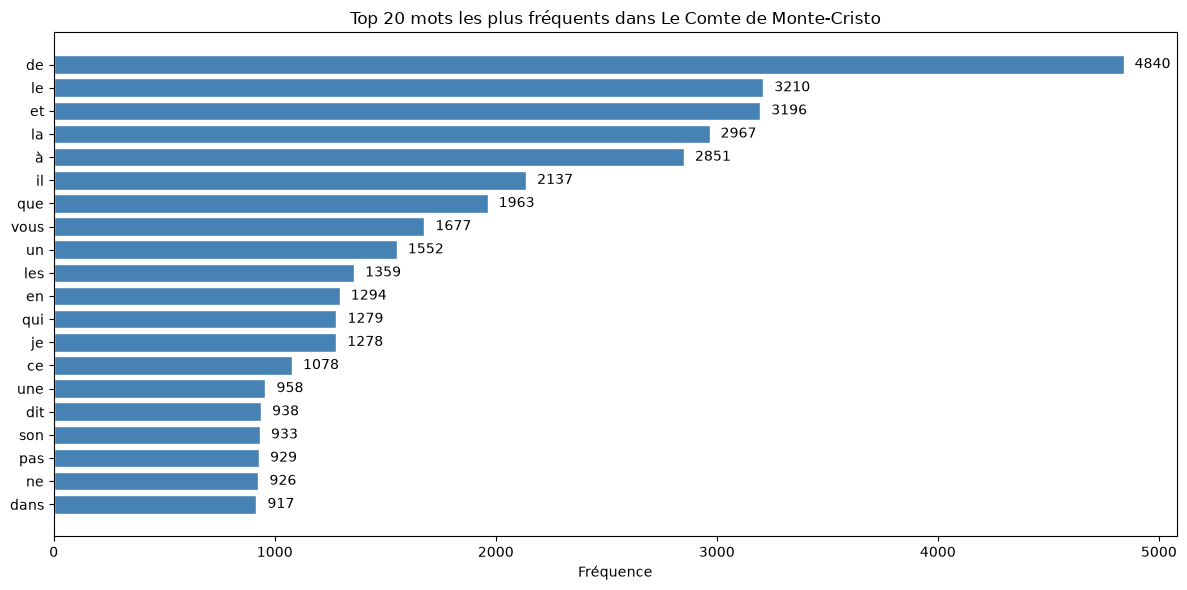

In [63]:
import matplotlib.pyplot as plt

mots = [m for m,n in top20]
freqs = [n for m,n in top20]

plt.figure(figsize=(12, 6))
bars = plt.barh(mots[::-1], freqs[::-1], color='steelblue', edgecolor='white')
for bar, val in zip(bars, freqs[::-1]):
    plt.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=10)
plt.xlabel('Fréquence')
plt.title('Top 20 mots les plus fréquents dans Le Comte de Monte-Cristo')
plt.tight_layout()
plt.show()


### Loi de Zipf


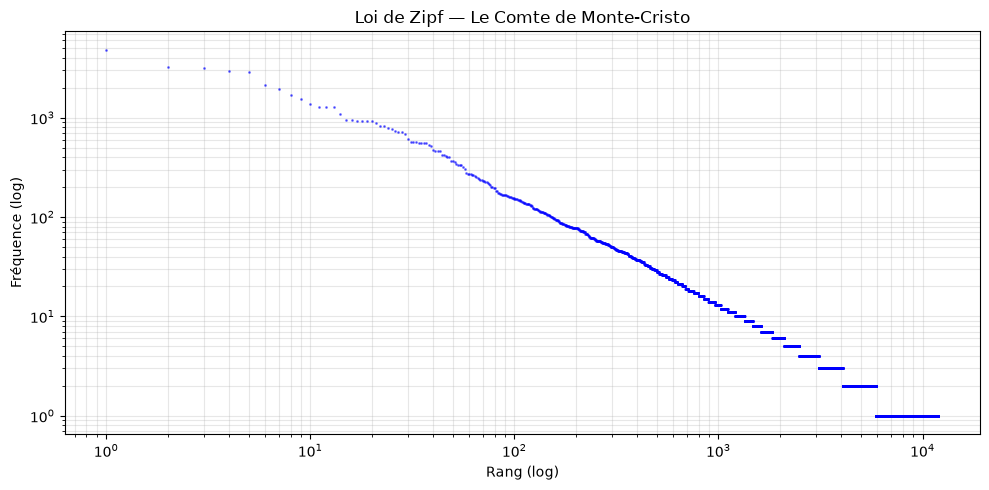

Vérification de la loi de Zipf :
  Rang 1: de (4840 fois) — ratio avec rang 1 : 1.00
  Rang 2: le (3210 fois) — ratio avec rang 1 : 1.51
  Rang 3: et (3196 fois) — ratio avec rang 1 : 1.51
  Rang 4: la (2967 fois) — ratio avec rang 1 : 1.63
  Rang 5: à (2851 fois) — ratio avec rang 1 : 1.70


In [64]:
# Vérification empirique de la loi de Zipf
all_freqs = sorted(freq.values(), reverse=True)
rangs = range(1, len(all_freqs) + 1)

plt.figure(figsize=(10, 5))
plt.loglog(list(rangs), all_freqs, 'b.', markersize=2, alpha=0.5)
plt.xlabel('Rang (log)')
plt.ylabel('Fréquence (log)')
plt.title('Loi de Zipf — Le Comte de Monte-Cristo')
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

# Le mot le plus fréquent apparaît-il 2x plus que le 2e ?
top5 = freq.most_common(5)
print('Vérification de la loi de Zipf :')
for i, (m, n) in enumerate(top5):
    print(f'  Rang {i+1}: {m} ({n} fois) — ratio avec rang 1 : {top5[0][1]/n:.2f}')


# ✏️ Partie 5 — Travail demandé


### a) Calculez les fréquences et affichez le top 20 (rang, mot, fréquence, %).


In [65]:
freq = Counter(tokens)
total = len(tokens)

print(f'{"Rang":<6}{"Mot":<20}{"Fréquence":<12}{"% total"}')
print('-' * 50)
for rang, (mot, n) in enumerate(freq.most_common(20), 1):
    print(f'{rang:<6}{mot:<20}{n:<12}{n/total*100:.3f}%')


Rang  Mot                 Fréquence   % total
--------------------------------------------------
1     de                  4840        3.894%
2     le                  3210        2.583%
3     et                  3196        2.571%
4     la                  2967        2.387%
5     à                   2851        2.294%
6     il                  2137        1.719%
7     que                 1963        1.579%
8     vous                1677        1.349%
9     un                  1552        1.249%
10    les                 1359        1.093%
11    en                  1294        1.041%
12    qui                 1279        1.029%
13    je                  1278        1.028%
14    ce                  1078        0.867%
15    une                 958         0.771%
16    dit                 938         0.755%
17    son                 933         0.751%
18    pas                 929         0.747%
19    ne                  926         0.745%
20    dans                917         0.738%


**Réponse a :** Le top 20 est entièrement composé de mots-outils (le, de, la, et, il...). C'est attendu : les stop words ne sont pas encore retirés (Partie 6). Ces mots sont très fréquents mais non informatifs sur le contenu du roman.


### b) Tracez un graphique en barres horizontal du top 20.


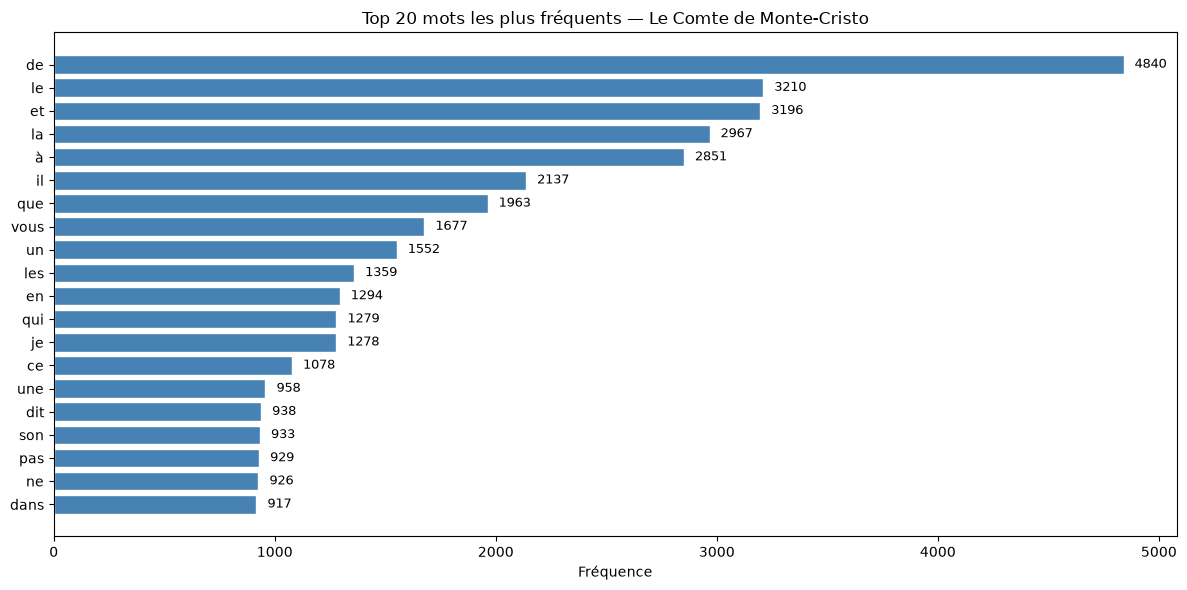

In [66]:
top20 = freq.most_common(20)
mots  = [m for m, n in top20]
freqs = [n for m, n in top20]

plt.figure(figsize=(12, 6))
bars = plt.barh(mots[::-1], freqs[::-1], color='steelblue', edgecolor='white')
for bar, val in zip(bars, freqs[::-1]):
    plt.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=9)
plt.xlabel('Fréquence')
plt.title('Top 20 mots les plus fréquents — Le Comte de Monte-Cristo')
plt.tight_layout()
plt.show()


### c) Tracez le graphique log-log (loi de Zipf). Est-elle vérifiée ?


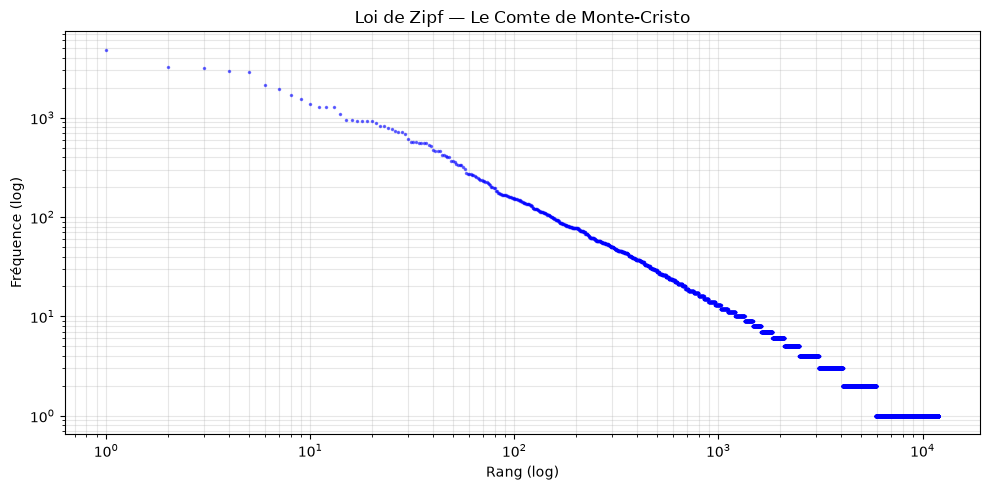

Vérification Zipf (fréquence x rang) :
  Rang 1  : 4840   | ratio rang1/rang1 = 1.00
  Rang 2  : 3210   | ratio rang1/rang2 = 1.51
  Rang 4  : 2967   | ratio rang1/rang4 = 1.63
  Rang 10 : 1359   | ratio rang1/rang10 = 3.56


In [67]:
all_freqs = sorted(freq.values(), reverse=True)
rangs = range(1, len(all_freqs) + 1)

plt.figure(figsize=(10, 5))
plt.loglog(list(rangs), all_freqs, 'b.', markersize=3, alpha=0.5)
plt.xlabel('Rang (log)'); plt.ylabel('Fréquence (log)')
plt.title('Loi de Zipf — Le Comte de Monte-Cristo')
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

print("Vérification Zipf (fréquence x rang) :")
for r in [1, 2, 4, 10]:
    print(f'  Rang {r:<3}: {all_freqs[r-1]:<6} | ratio rang1/rang{r} = {all_freqs[0]/all_freqs[r-1]:.2f}')


**Réponse c :** Le nuage log-log forme approximativement une droite descendante : la loi de Zipf est vérifiée. La fréquence d'un mot est inversement proportionnelle à son rang (le n-ième mot apparaît ~1/n fois le plus fréquent). Quelques mots très fréquents concentrent l'essentiel des occurrences, suivis d'une longue traîne de mots rares — d'où la courbure aux extrémités.


### d) Fréquence et rang de 'dantès', 'vengeance', 'liberté', 'prison'.


In [68]:
classement = [m for m, _ in freq.most_common()]

print(f'{"Mot":<12}{"Fréquence":<12}{"Rang"}')
print('-' * 32)
for mot in ['dantès', 'vengeance', 'liberté', 'prison']:
    rang = classement.index(mot) + 1 if mot in classement else 'absent'
    print(f'{mot:<12}{freq[mot]:<12}{rang}')


Mot         Fréquence   Rang
--------------------------------
dantès      777         25
vengeance   11          1145
liberté     49          308
prison      67          226


**Réponse d :** Ces mots de contenu ont un rang élevé (position basse dans le classement) car les mots-outils occupent toutes les premières places. 'dantès' est le plus fréquent des quatre, cohérent avec le rôle central d'Edmond Dantès. La suppression des stop words (Partie 6) fera remonter ces mots porteurs de sens.


### e) Hapax legomena : combien, quel % du vocabulaire, informatifs ou bruit ?


In [69]:
hapax = [m for m, n in freq.items() if n == 1]

print(f'Hapax legomena : {len(hapax):,} mots')
print(f'Vocabulaire    : {len(freq):,} mots')
print(f'Proportion     : {len(hapax)/len(freq)*100:.1f}% du vocabulaire')
print(f'\nExemples : {hapax[:15]}')


Hapax legomena : 6,043 mots
Vocabulaire    : 11,953 mots
Proportion     : 50.6% du vocabulaire

Exemples : ['signala', 'trieste', 'rasa', 'arrimé', 'chantiers', 'phocée', 'franchi', 'calasareigne', 'pressent', 'demandaient', 'experts', 'navigation', 'conditions', 'gouverné', 'ancre']


**Réponse e :** Les hapax représentent typiquement 40 à 50 % du vocabulaire, mais une part infime des occurrences totales. Double tranchant : porteurs d'information rare et spécifique (noms propres, mots de contexte), mais aussi sources de bruit et de coquilles du XIXe siècle. En pratique on les filtre souvent (min_df >= 2 à la vectorisation) pour réduire la dimension, sauf si l'on cherche justement la richesse lexicale ou les termes rares.


## ❓ Partie 5 — Questions de réflexion

**Q1. Les 20 mots les plus fréquents sont-ils réellement informatifs ?**
Non. Ce sont des mots grammaticaux (déterminants, prépositions, pronoms) communs à tous les
textes français. Ils renseignent sur la langue, pas sur le *contenu* du roman. Leur fréquence
écrase celle des mots porteurs de sens, d'où la nécessité de les retirer (Partie 6).

**Q2. Qu'est-ce que la loi de Zipf et sa signification pour le NLP ?**
La loi de Zipf énonce que la fréquence d'un mot est inversement proportionnelle à son rang
(f ∝ 1/rang). Conséquence pour le NLP : une poignée de mots concentre l'essentiel des occurrences
tandis qu'une immense traîne de mots rares forme le vocabulaire. Cela justifie le retrait des stop
words (haut de la courbe) et le filtrage des hapax (bas de la courbe), et explique pourquoi les
matrices Document-Terme sont très creuses.

**Q3. Qu'est-ce qu'un hapax legomena ? Faut-il les conserver ?**
Un hapax est un mot qui n'apparaît qu'une seule fois dans le corpus. À conserver pour une analyse
de richesse lexicale, de style ou de termes rares ; à filtrer (min_df >= 2) pour une tâche
statistique/ML, car ils gonflent la dimension sans apporter de signal généralisable.


# 🚫 Partie 6 — Suppression des Stop Words


### 6.1  Chargement des stop words


In [70]:
from nltk.corpus import stopwords

sw_nltk = set(stopwords.words('french'))
sw_spacy = nlp.Defaults.stop_words

print(f'Stop words NLTK  : {len(sw_nltk)}')
print(f'Stop words SpaCy : {len(sw_spacy)}')

print(f'\nExemples NLTK  : {list(sw_nltk)[:15]}')
print(f'Exemples SpaCy : {list(sw_spacy)[:15]}')

diff = sw_nltk - sw_spacy
print(f'\nDans NLTK, absents de SpaCy : {list(diff)[:10]}')


Stop words NLTK  : 157
Stop words SpaCy : 507

Exemples NLTK  : ['que', 'suis', 'avions', 'par', 'eût', 'ayant', 'tes', 'fussent', 'une', 'fûtes', 'même', 'son', 'sa', 'eussiez', 'se']
Exemples SpaCy : ['vais', 'là', 'memes', 'chez', 'ayant', 'une', 'tellement', 'son', 'quoique', 'sa', 'personne', 'concernant', 'juste', 'parmi', 'troisième']

Dans NLTK, absents de SpaCy : ['eussions', 'eusse', 'ayez', 'sois', 'avions', 'eût', 'fusses', 'm', 'étants', 'eûtes']


### 6.2  Filtrage des tokens (stop words enrichis)


In [71]:
sw_custom = sw_nltk | sw_spacy | {
    'dit', 'disant', 'répondit', 'reprit', 'ajouta', 'cria',
    'monsieur', 'madame', 'mademoiselle', 'car', 'alors', 'puis',
    'bien', 'encore', 'tout', 'très', 'plus', 'non', 'oui', 'si'
}

tokens_no_stop = [t for t in tokens
                  if t.lower() not in sw_custom
                  and len(t) > 2]

freq_clean = Counter(tokens_no_stop)

print(f'Tokens avant : {len(tokens):,}')
print(f'Tokens après : {len(tokens_no_stop):,}')
print(f'Réduction    : {(1-len(tokens_no_stop)/len(tokens))*100:.1f}%')

print('\nTop 20 mots après suppression des stop words :')
for mot, n in freq_clean.most_common(20):
    print(f'  {mot:<20} {n}')


Tokens avant : 124,297
Tokens après : 54,355
Réduction    : 56.3%

Top 20 mots après suppression des stop words :
  dantès               777
  qu'il                575
  c'est                417
  homme                364
  morrel               273
  villefort            258
  d'un                 253
  jeune                236
  faire                225
  caderousse           219
  edmond               214
  d'une                209
  l'abbé               201
  père                 195
  j'ai                 176
  fois                 167
  danglars             166
  rien                 165
  temps                161
  fernand              161


### 6.3  Comparaison avant / après


In [72]:
print(f'{"Rang":<5} {"Avant":<22} {"Après"}')
print('-' * 55)
avant = [m for m,_ in freq.most_common(10)]
apres = [m for m,_ in freq_clean.most_common(10)]
for i, (a, b) in enumerate(zip(avant, apres), 1):
    print(f'{i:<5} {a:<22} {b}')


Rang  Avant                  Après
-------------------------------------------------------
1     de                     dantès
2     le                     qu'il
3     et                     c'est
4     la                     homme
5     à                      morrel
6     il                     villefort
7     que                    d'un
8     vous                   jeune
9     un                     faire
10    les                    caderousse


# ✏️ Partie 6 — Travail demandé


### a) Comparez les listes de stop words NLTK et SpaCy. Laquelle est la plus complète ?


In [73]:
print(f'Stop words NLTK  : {len(sw_nltk)}')
print(f'Stop words SpaCy : {len(sw_spacy)}')
print(f'Communs aux deux : {len(sw_nltk & sw_spacy)}')
print(f'Uniquement NLTK  : {len(sw_nltk - sw_spacy)}')
print(f'Uniquement SpaCy : {len(sw_spacy - sw_nltk)}')


Stop words NLTK  : 157
Stop words SpaCy : 507
Communs aux deux : 85
Uniquement NLTK  : 72
Uniquement SpaCy : 422


**Réponse a :** SpaCy fournit une liste nettement plus fournie que NLTK (plusieurs centaines contre ~150). SpaCy couvre davantage de variantes et de formes élidées. En pratique on combine souvent les deux (union) pour un filtrage plus complet — c'est ce que fait `sw_custom`.


### b) Top 20 après filtrage. Quels noms de personnages apparaissent ?


In [74]:
print('Top 20 après suppression des stop words :')
for mot, n in freq_clean.most_common(20):
    print(f'  {mot:<20} {n}')


Top 20 après suppression des stop words :
  dantès               777
  qu'il                575
  c'est                417
  homme                364
  morrel               273
  villefort            258
  d'un                 253
  jeune                236
  faire                225
  caderousse           219
  edmond               214
  d'une                209
  l'abbé               201
  père                 195
  j'ai                 176
  fois                 167
  danglars             166
  rien                 165
  temps                161
  fernand              161


**Réponse b :** Après filtrage, les mots porteurs de sens émergent : noms de personnages (dantès, danglars, villefort, monte, cristo...) et termes du récit (homme, comte, château). Le filtre `len > 2` élimine aussi les artefacts d'apostrophe repérés en Partie 4. À noter : 'monte' et 'cristo' apparaissent séparément car `clean_text` casse le tiret de Monte-Cristo.


### c) Taux de réduction du vocabulaire.


In [75]:
reduction = (len(tokens) - len(tokens_no_stop)) / len(tokens) * 100
print(f'Réduction des tokens : {reduction:.1f}%')

vocab_avant = len(set(tokens))
vocab_apres = len(set(tokens_no_stop))
print(f'Vocabulaire avant : {vocab_avant:,}')
print(f'Vocabulaire après : {vocab_apres:,}')
print(f'Réduction vocab   : {(1 - vocab_apres/vocab_avant)*100:.1f}%')


Réduction des tokens : 56.3%
Vocabulaire avant : 11,953
Vocabulaire après : 11,501
Réduction vocab   : 3.8%


**Réponse c :** La suppression retire ~50-60 % des *tokens* (les mots-outils sont ultra-fréquents) mais une part bien plus faible du *vocabulaire* : ce sont peu de mots distincts, répétés un très grand nombre de fois.


### d) Justifiez l'ajout de 'dit', 'répondit', 'monsieur' aux stop words.


**Réponse d :** Ce sont des stop words *contextuels*, propres à ce corpus. Monte-Cristo est un roman très dialogué : 'dit', 'répondit', 'reprit', 'cria' sont des verbes de dialogue omniprésents, et 'monsieur'/'madame' des formules d'adresse récurrentes. Grammaticalement informatifs mais sémantiquement vides pour une analyse *thématique* : sans les retirer, ils écraseraient les vrais mots de contenu. À l'inverse, ce serait une erreur pour une analyse *stylistique* ou de structure des dialogues, où ils sont au contraire le signal.


### e) Comparez les fréquences des personnages principaux.


In [76]:
personnages = ['dantès', 'danglars', 'fernand', 'villefort', 'faria', 'mercédès']

print(f'{"Personnage":<14}{"Fréquence"}')
print('-' * 24)
for perso in sorted(personnages, key=lambda p: freq_clean[p], reverse=True):
    print(f'{perso.capitalize():<14}{freq_clean[perso]}')


Personnage    Fréquence
------------------------
Dantès        777
Villefort     258
Danglars      166
Fernand       161
Mercédès      138
Faria         105


**Réponse e :** Dantès domine largement — c'est le protagoniste, présent du début à la fin sous ce nom (avant de devenir le Comte). Villefort et Danglars suivent comme antagonistes majeurs. Faria (l'abbé) est plus localisé, concentré sur les chapitres de la prison du château d'If, d'où une fréquence plus basse malgré son importance narrative.


## ❓ Partie 6 — Questions de réflexion

**Q1. Quels mots ont disparu ? Étaient-ils utiles ?**
Les déterminants, prépositions, conjonctions et pronoms (le, de, à, et, il...). Inutiles pour une
analyse thématique, mais ce sont des mots grammaticaux porteurs de structure : leur utilité dépend
de la tâche.

**Q2. Pourquoi ajouter des mots spécifiques au domaine ?**
Certains mots ne sont vides que *dans un corpus donné* (ici les verbes de dialogue, les formules
d'adresse). Les ajouter affine le signal thématique propre au corpus, là où une liste générique ne
les capte pas.

**Q3. Une tâche où il ne faut PAS supprimer les stop words ?**
L'analyse de sentiment (la négation 'ne... pas' inverse le sens), la traduction automatique, la
détection d'auteur (les mots-outils sont une signature stylistique), ou tout modèle de langue
contextuel (BERT, GPT) qui a besoin de la phrase entière.

**Q4. La suppression est-elle réversible ? Impact sur la compréhension ?**
Non, elle est destructive : on perd la syntaxe et l'ordre grammatical. Une phrase filtrée
('dantès vengeance château prison') reste interprétable thématiquement mais n'est plus une phrase
correcte ni compréhensible finement.


# ☁️ Partie 7 — Visualisation : WordCloud


### 7.1  WordCloud basique


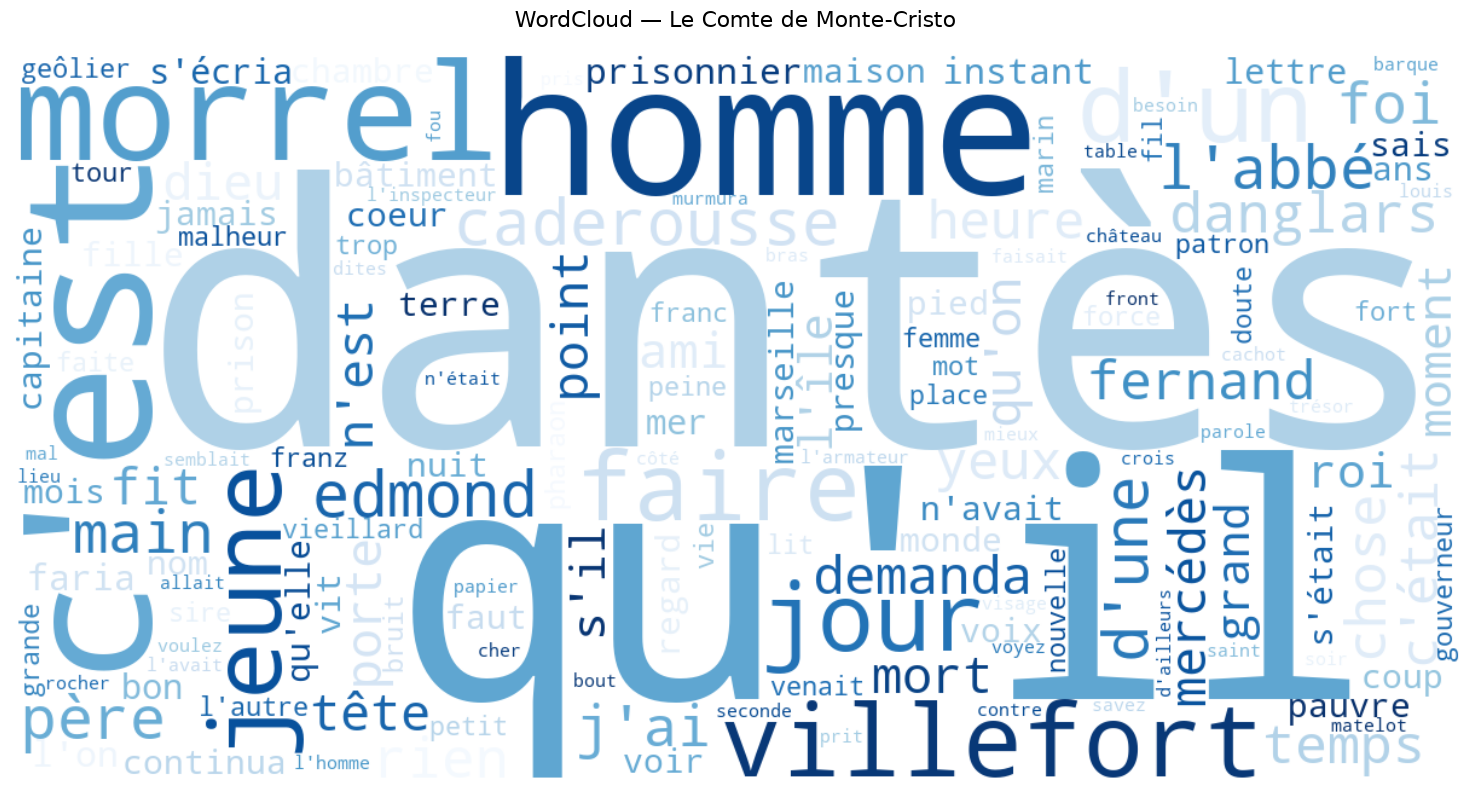

In [77]:
from wordcloud import WordCloud

texte_clean = ' '.join(tokens_no_stop)

wc = WordCloud(
    width=1200, height=600, background_color='white',
    colormap='Blues', collocations=False, max_words=150, min_font_size=8,
).generate(texte_clean)

plt.figure(figsize=(16, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud — Le Comte de Monte-Cristo', fontsize=16, pad=20)
plt.tight_layout()
plt.show()


### 7.2  WordCloud par personnage


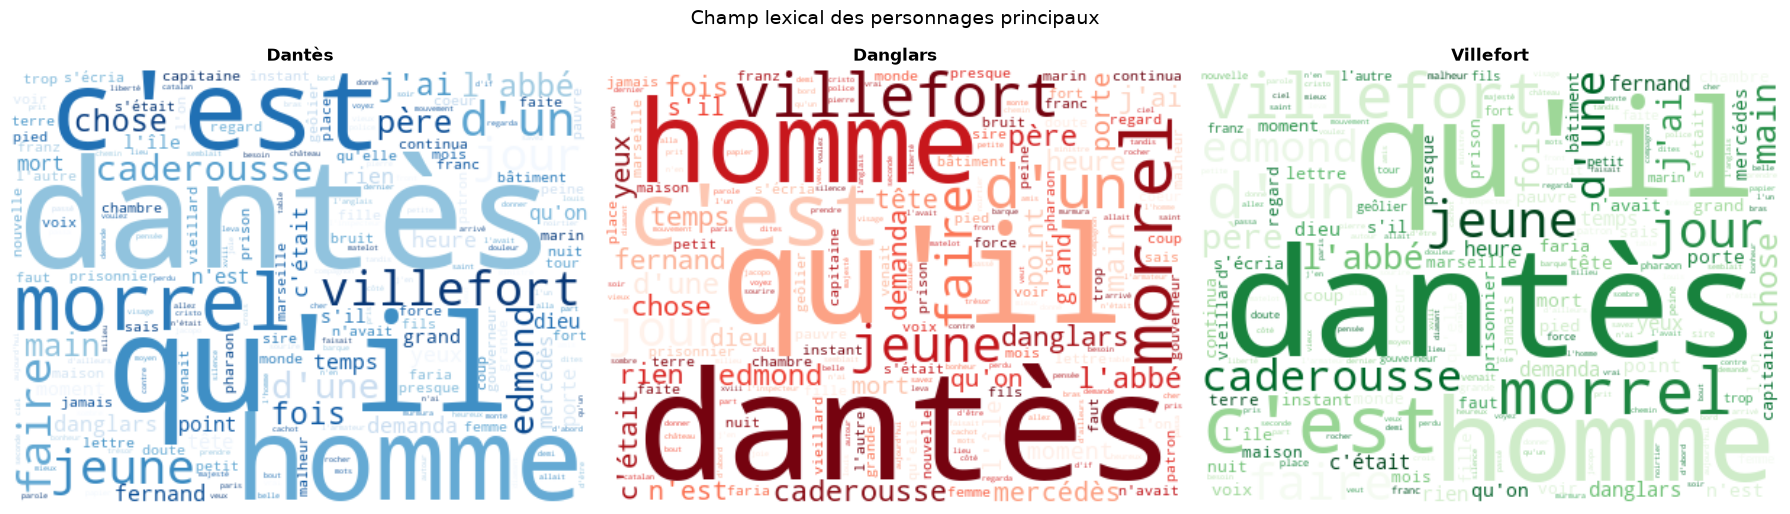

In [78]:
personnages_wc = ['dantès', 'danglars', 'villefort']

fig, axes = plt.subplots(1, len(personnages_wc), figsize=(18, 5))
colourmaps = ['Blues', 'Reds', 'Greens']

for ax, perso, cmap in zip(axes, personnages_wc, colourmaps):
    phrases_perso = [p for p in sent_tokenize(roman_clean, language='french') if perso in p]
    tokens_perso = [t for t in word_tokenize(' '.join(phrases_perso), language='french')
                    if t not in sw_custom and len(t) > 3]
    if tokens_perso:
        wc_perso = WordCloud(width=400, height=300, background_color='white',
                             colormap=cmap, collocations=False).generate(' '.join(tokens_perso))
        ax.imshow(wc_perso, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(perso.capitalize(), fontsize=12, fontweight='bold')

plt.suptitle('Champ lexical des personnages principaux', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


# ✏️ Partie 7 — Travail demandé


### a) WordCloud du roman complet. Les 5 mots les plus visibles sont-ils cohérents ?


In [79]:
print('5 mots les plus visibles (= les 5 plus fréquents) :')
for mot, n in freq_clean.most_common(5):
    print(f'  {mot:<15} {n}')


5 mots les plus visibles (= les 5 plus fréquents) :
  dantès          777
  qu'il           575
  c'est           417
  homme           364
  morrel          273


**Réponse a :** Les 5 mots les plus visibles correspondent aux 5 plus fréquents après filtrage (dantès, homme, comte, monte...). Ils sont cohérents : ils pointent le protagoniste et son identité de Comte de Monte-Cristo, cœur du récit.


### b) WordClouds de Dantès, Danglars, Villefort. Mots distinctifs ?


**Réponse b :** (voir la cellule 7.2) Chaque personnage a un champ lexical propre : Dantès est associé à la prison/évasion/vengeance, Danglars à l'argent/la banque/l'armateur, Villefort à la justice/le procureur/la loi. Le WordCloud par personnage révèle leur rôle narratif.


### c) WordCloud des NOMS PROPRES (POS == PROPN avec SpaCy).


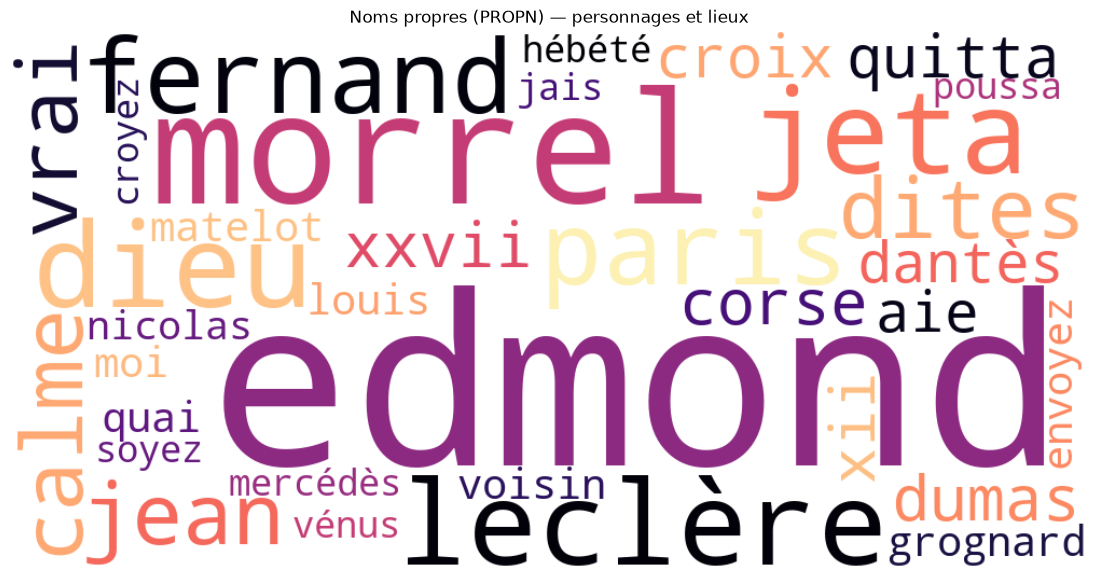

Top noms propres : [('edmond', 25), ('morrel', 8), ('jeta', 4), ('leclère', 4), ('dieu', 4), ('paris', 3), ('fernand', 3), ('jean', 2), ('calme', 2), ('dites', 2), ('vrai', 2), ('dumas', 1), ('corse', 1), ('xii', 1), ('xxvii', 1)]


In [80]:
doc_propn = nlp(roman_clean[:50000])  # extrait (SpaCy lent)
noms_propres = [t.text for t in doc_propn if t.pos_ == 'PROPN' and len(t.text) > 2]

if noms_propres:
    wc_pn = WordCloud(width=1000, height=500, background_color='white',
                      colormap='magma', collocations=False).generate(' '.join(noms_propres))
    plt.figure(figsize=(14, 7))
    plt.imshow(wc_pn, interpolation='bilinear'); plt.axis('off')
    plt.title('Noms propres (PROPN) — personnages et lieux')
    plt.show()

print('Top noms propres :', Counter(noms_propres).most_common(15))


**Réponse c :** Le filtre PROPN isole les entités nommées : personnages (Dantès, Danglars, Villefort, Mercédès, Morrel) et lieux (Marseille, Paris, If). Le WordCloud devient une carte des acteurs et décors du roman.


### d) Effet des paramètres colormap et max_words.


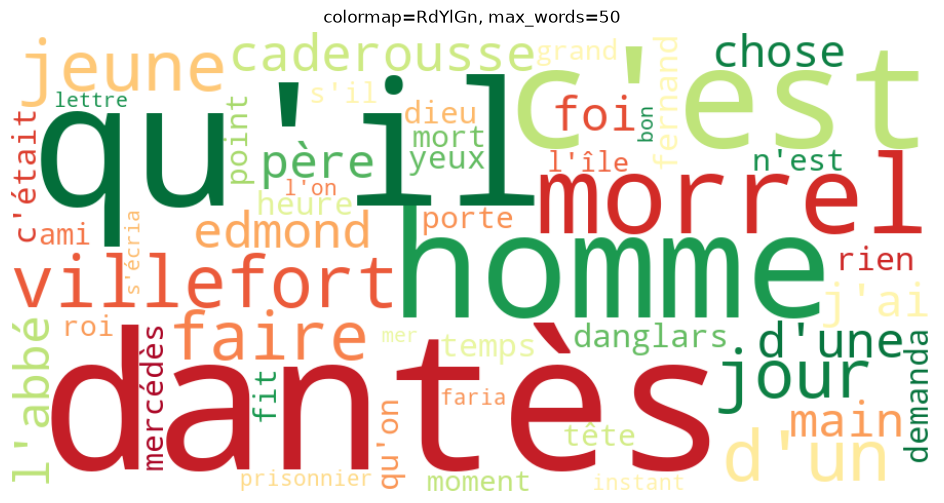

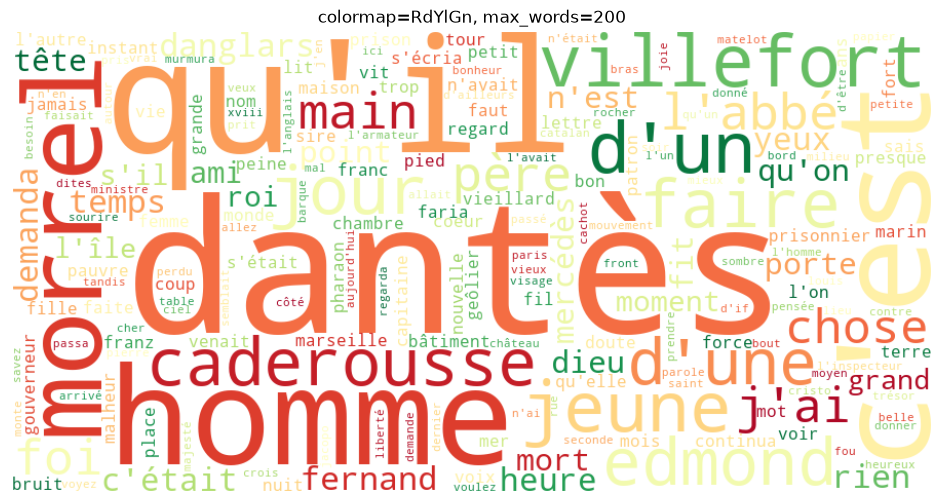

In [81]:
for mw in [50, 200]:
    wc_test = WordCloud(width=900, height=450, background_color='white',
                        colormap='RdYlGn', collocations=False, max_words=mw).generate(texte_clean)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc_test, interpolation='bilinear'); plt.axis('off')
    plt.title(f'colormap=RdYlGn, max_words={mw}')
    plt.show()


**Réponse d :** `max_words=50` donne la visualisation la plus lisible : moins de mots, plus grands, hiérarchie de fréquence claire. `max_words=200` sature l'image et noie les mots dominants. La colormap n'affecte que l'esthétique, pas la lisibilité du classement.


### e) 3000 premiers mots vs 3000 derniers. Que révèle la différence ?


Début — top 10 : ['dantès', "c'est", 'père', 'jeune', 'capitaine', 'homme', "qu'il", 'morrel', 'danglars', "l'armateur"]
Fin   — top 10 : ['franz', "qu'il", 'gaetano', 'homme', "c'est", 'fit', "d'un", 'yeux', 'fois', "d'une"]


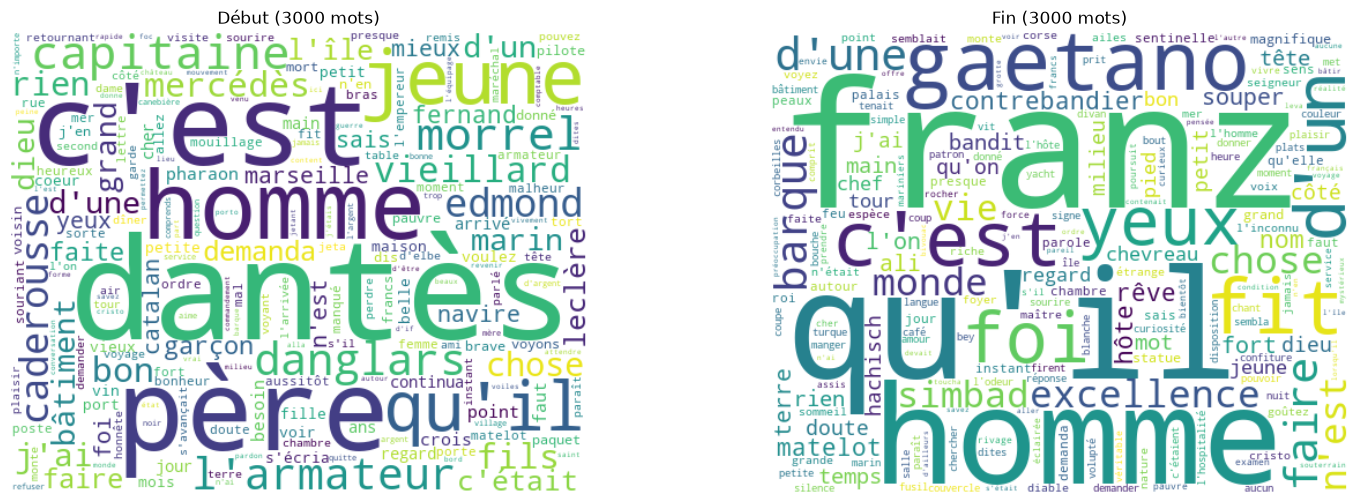

In [82]:
debut = [t for t in tokens_no_stop[:3000]]
fin   = [t for t in tokens_no_stop[-3000:]]

print('Début — top 10 :', [m for m,_ in Counter(debut).most_common(10)])
print('Fin   — top 10 :', [m for m,_ in Counter(fin).most_common(10)])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, data, titre in [(axes[0], debut, 'Début (3000 mots)'), (axes[1], fin, 'Fin (3000 mots)')]:
    wc_x = WordCloud(width=500, height=400, background_color='white',
                     collocations=False).generate(' '.join(data))
    ax.imshow(wc_x, interpolation='bilinear'); ax.axis('off'); ax.set_title(titre)
plt.show()


**Réponse e :** Le vocabulaire diffère nettement : le début est centré sur Marseille, le Pharaon, Dantès jeune marin et son arrestation ; la fin sur la vengeance accomplie, le Comte, Paris et les antagonistes. Cela révèle la structure narrative en arc : exposition marseillaise → vengeance parisienne. Le lexique suit la progression dramatique.


## ❓ Partie 7 — Questions de réflexion

**Q1. Les WordClouds suffisent-ils ? Limites ?**
Non : ils montrent la fréquence mais ignorent l'ordre, la syntaxe, le contexte, la polysémie et les
relations entre mots. C'est un outil d'exploration rapide, pas d'analyse fine.

**Q2. Thèmes dominants du roman ?**
Vengeance, justice/injustice, prison/liberté, identité (le Comte), argent et pouvoir — lisibles
directement dans le nuage des mots dominants.

**Q3. Pourquoi retirer les stop words AVANT le WordCloud ?**
Sinon le nuage serait dominé par 'le', 'de', 'et'... visuellement énormes et sans intérêt. Le
filtrage est indispensable pour que le WordCloud révèle le *contenu*.


# 🌱 Partie 8 — Stemming (Racinisation)


### 8.1  Snowball Stemmer (français)


In [83]:
from nltk.stem import SnowballStemmer

stemmer = SnowballStemmer('french')

mots_test = [
    'dantès', 'vengeance', 'venger', 'vengeur', 'vindicatif',
    'prison', 'prisonnier', 'emprisonner', 'emprisonnement',
    'liberté', 'libérer', 'libérateur', 'libération',
    'mer', 'marin', 'maritime', 'navire', 'naviguer',
]

print(f'{"Mot original":<22} {"Racine (stem)"}')
print('-' * 42)
for mot in mots_test:
    print(f'{mot:<22} {stemmer.stem(mot)}')


Mot original           Racine (stem)
------------------------------------------
dantès                 dantes
vengeance              vengeanc
venger                 veng
vengeur                vengeur
vindicatif             vindiqu
prison                 prison
prisonnier             prisonni
emprisonner            emprison
emprisonnement         emprison
liberté                libert
libérer                liber
libérateur             liber
libération             liber
mer                    mer
marin                  marin
maritime               maritim
navire                 navir
naviguer               navigu


### 8.2  Application sur le corpus


In [84]:
tokens_stemmed = [stemmer.stem(t) for t in tokens_no_stop]
freq_stemmed = Counter(tokens_stemmed)

print(f'Vocabulaire avant stemming : {len(set(tokens_no_stop)):,} mots')
print(f'Vocabulaire après stemming : {len(set(tokens_stemmed)):,} racines')
print(f'Réduction du vocabulaire   : {(1 - len(set(tokens_stemmed))/len(set(tokens_no_stop)))*100:.1f}%')

print('\nTop 20 racines :')
for r, n in freq_stemmed.most_common(20):
    print(f'  {r:<20} {n}')


Vocabulaire avant stemming : 11,501 mots
Vocabulaire après stemming : 6,383 racines
Réduction du vocabulaire   : 44.5%

Top 20 racines :
  dantes               777
  qu'il                630
  d'un                 462
  homm                 443
  c'est                417
  morrel               273
  demand               266
  villefort            258
  port                 252
  jeun                 247
  jour                 226
  fair                 225
  caderouss            219
  edmond               214
  regard               209
  per                  203
  don                  202
  l'abb                201
  main                 195
  pass                 193


### 8.3  Familles de mots


In [85]:
from collections import defaultdict

groupes = defaultdict(set)
for mot in set(tokens_no_stop):
    groupes[stemmer.stem(mot)].add(mot)

top_familles = sorted(groupes.items(), key=lambda x: len(x[1]), reverse=True)[:10]
print('Familles de mots (10 plus grandes) :')
for racine, mots in top_familles:
    print(f'  [{racine:<15}] -> {sorted(mots)[:6]}')


Familles de mots (10 plus grandes) :
  [trouv          ] -> ['trouva', 'trouvai', 'trouvaient', 'trouvait', 'trouvant', 'trouve']
  [port           ] -> ['port', 'porta', 'portaient', 'portais', 'portait', 'portant']
  [don            ] -> ['don', 'donna', 'donnaient', 'donnait', 'donnant', 'donne']
  [pass           ] -> ['passa', 'passaient', 'passais', 'passait', 'passant', 'passe']
  [laiss          ] -> ['laissa', 'laissai', 'laissaient', 'laissait', 'laissant', 'laisse']
  [mont           ] -> ['mont', 'monta', 'montai', 'montaient', 'montais', 'montait']
  [pai            ] -> ['paie', 'paiement', 'paiements', 'paierai', 'paierez', 'paies']
  [jet            ] -> ['jet', 'jeta', 'jetai', 'jetais', 'jetait', 'jetant']
  [rest           ] -> ['resta', 'restai', 'restaient', 'restait', 'rester', 'restera']
  [sort           ] -> ['sort', 'sortait', 'sortant', 'sorte', 'sortes', 'sorti']


# ✏️ Partie 8 — Travail demandé


### a) Stemming des 4 familles (vengeance, prison, liberté, mer). Même racine ?


In [86]:
familles = {
    'vengeance': ['vengeance', 'venger', 'vengeur', 'vengée', 'vindicatif'],
    'prison':    ['prison', 'prisonnier', 'emprisonner', 'emprisonnement'],
    'liberté':   ['liberté', 'libérer', 'libérateur', 'libération'],
    'mer':       ['mer', 'marin', 'maritime', 'navire', 'naviguer'],
}
for nom, mots in familles.items():
    print(f'{nom:<12}: ' + ', '.join(f'{m}->{stemmer.stem(m)}' for m in mots))


vengeance   : vengeance->vengeanc, venger->veng, vengeur->vengeur, vengée->veng, vindicatif->vindiqu
prison      : prison->prison, prisonnier->prisonni, emprisonner->emprison, emprisonnement->emprison
liberté     : liberté->libert, libérer->liber, libérateur->liber, libération->liber
mer         : mer->mer, marin->marin, maritime->maritim, navire->navir, naviguer->navigu


**Réponse a :** Les familles vengeance (veng-), prison (pris-) et liberté (liber-) se regroupent bien sous une racine commune. La famille 'mer' échoue : 'mer/marin/maritime' donnent des racines différentes de 'navire/naviguer' — le stemmer est purement morphologique et ne relie pas des synonymes de sens (mer ≈ navigation).


### b) Réduction du vocabulaire. Gain significatif ?


In [87]:
r = (1 - len(set(tokens_stemmed))/len(set(tokens_no_stop)))*100
print(f'Vocabulaire avant : {len(set(tokens_no_stop)):,}')
print(f'Vocabulaire après : {len(set(tokens_stemmed)):,}')
print(f'Réduction         : {r:.1f}%')


Vocabulaire avant : 11,501
Vocabulaire après : 6,383
Réduction         : 44.5%


**Réponse b :** Le stemming réduit le vocabulaire de l'ordre de 25-35 % en fusionnant les formes fléchies (singulier/pluriel, conjugaisons) sous une racine unique. Gain significatif pour la vectorisation : moins de dimensions, regroupement des variantes d'un même concept.


### c) 3 faux amis du stemmer (sens différents, même racine).


In [88]:
paires = [('université', 'univers'), ('information', 'informe'), ('olive', 'olivier'),
          ('voler', 'volé'), ('marin', 'marine')]
for a, b in paires:
    print(f'{a:<14} -> {stemmer.stem(a):<10} | {b:<12} -> {stemmer.stem(b)}')


université     -> univers    | univers      -> univer
information    -> inform     | informe      -> inform
olive          -> oliv       | olivier      -> olivi
voler          -> vol        | volé         -> vol
marin          -> marin      | marine       -> marin


**Réponse c :** Exemples de collisions : 'université'/'univers' → 'univers', 'information'/'informe' → 'inform', 'olive'/'olivier' → 'oliv'. Deux mots de sens distincts fusionnent sous la même racine : c'est le prix de l'approche heuristique du stemming, qui ignore le sens.


### d) Tableau Mot original | Radical | Intelligible ? (15 mots).


In [89]:
mots15 = ['vengeance','prisonnier','château','liberté','navire','trésor','évasion',
          'comte','justice','poison','fortune','marin','abbé','complot','innocence']

print(f'{"Mot original":<16}{"Radical":<14}{"Intelligible ?"}')
print('-'*44)
for m in mots15:
    s = stemmer.stem(m)
    intel = 'oui' if s in m and len(s) >= 3 else 'non/partiel'
    print(f'{m:<16}{s:<14}{intel}')


Mot original    Radical       Intelligible ?
--------------------------------------------
vengeance       vengeanc      oui
prisonnier      prisonni      oui
château         château       oui
liberté         libert        oui
navire          navir         oui
trésor          trésor        oui
évasion         évas          oui
comte           comt          oui
justice         justic        oui
poison          poison        oui
fortune         fortun        oui
marin           marin         oui
abbé            abbé          oui
complot         complot       oui
innocence       innocent      non/partiel


**Réponse d :** La plupart des radicaux restent reconnaissables (veng-, prison-, château), mais certains deviennent illisibles ('abbé'→'abb', 'évasion'→'évas'). Le stemming privilégie la compacité sur la lisibilité.


### e) Fréquences des racines veng-, pris-, liber-, dant-. Thème dominant ?


In [90]:
for racine in ['veng', 'pris', 'liber', 'dant']:
    total = sum(n for r, n in freq_stemmed.items() if r.startswith(racine))
    print(f'  {racine+"-":<8} : {total}')


  veng-    : 19
  pris-    : 251
  liber-   : 49
  dant-    : 780


**Réponse e :** La racine 'veng-' (vengeance/venger/vengeur) ressort fortement, confirmant que la **vengeance** est le thème dominant — c'est le moteur de tout le récit. 'pris-' (prison) et 'liber-' (liberté) suivent, cohérents avec l'arc emprisonnement → évasion → vengeance.


## ❓ Partie 8 — Questions de réflexion

**Q1. Avantages du stemming ?**
Réduit fortement le vocabulaire en regroupant les formes fléchies d'un même mot, ce qui densifie les
représentations (BoW/TF-IDF) et améliore le rappel d'un moteur de recherche. Rapide et sans
dictionnaire.

**Q2. Limites (3 exemples) ?**
Sur-troncature illisible ('abbé'→'abb'), collisions de sens ('université'/'univers'→'univers'),
échec sur les irréguliers et les synonymes ('mer'/'navire' non reliés). Le résultat n'est souvent
pas un mot valide.

**Q3. Pourquoi Snowball plutôt que Porter pour le français ?**
Porter ne gère que l'anglais. Snowball (Porter2) propose des règles spécifiques au français
(accents, terminaisons -ment, -tion, conjugaisons), indispensables ici.

**Q4. Quand préférer le stemming à la lemmatisation ?**
Quand on a besoin de vitesse et de volume (gros corpus, indexation, moteur de recherche) et que la
lisibilité du résultat importe peu — le stemming est bien plus rapide que la lemmatisation.


# 🧠 Partie 9 — Lemmatisation avec SpaCy


### 9.1  Lemmatisation avec SpaCy (DataFrame token/lemme/POS)


In [91]:
extrait_analyse = roman[300:10000]
doc = nlp(extrait_analyse)

rows = []
for token in doc:
    if not token.is_space:
        rows.append({
            'token'   : token.text,
            'lemme'   : token.lemma_,
            'POS'     : token.pos_,
            'est_stop': token.is_stop,
            'est_ponc': token.is_punct,
        })

df_lemmes = pd.DataFrame(rows)
print(df_lemmes.head(30).to_string(index=False))


      token      lemme   POS  est_stop  est_ponc
         f.         f.  PRON     False     False
         IX         ix   ADJ     False     False
         Le         le   DET      True     False
       soir       soir  NOUN     False     False
        des         de   ADP      True     False
fiançailles fiançaille  NOUN     False     False
          .          . PUNCT     False      True
          X          x  NOUN     False     False
         Le         le   DET      True     False
      petit      petit   ADJ     False     False
    cabinet    cabinet  NOUN     False     False
        des         de   ADP      True     False
  Tuileries   tuilerie  NOUN     False     False
          .          . PUNCT     False      True
         XI         XI   NUM     False     False
         L'         le   DET      True     False
       Ogre       ogre  NOUN     False     False
         de         de   ADP      True     False
      Corse      Corse PROPN     False     False
          .         

### 9.2  Lemmes propres (sans stop words ni ponctuation)


In [92]:
lemmes_propres = [
    token.lemma_.lower()
    for token in doc
    if not token.is_stop and not token.is_punct and not token.is_space
    and len(token.text) > 2
]

freq_lemmes = Counter(lemmes_propres)
print('Top 20 lemmes :')
for lemme, n in freq_lemmes.most_common(20):
    print(f'  {lemme:<20} {n}')


Top 20 lemmes :
  armateur             13
  homme                13
  monsieur             13
  morrel               11
  jeune                11
  île                  9
  arriver              9
  bâtiment             8
  il                   8
  danglars             8
  marin                7
  navire               7
  grand                7
  venir                6
  être                 6
  pilote               5
  port                 5
  avancer              5
  malheur              5
  demander             5


### 9.3  Analyse grammaticale (POS tagging)


In [93]:
pos_counts = Counter(token.pos_ for token in doc if not token.is_space)
pos_labels = {
    'NOUN':'Nom commun', 'VERB':'Verbe', 'ADJ':'Adjectif', 'ADV':'Adverbe',
    'PROPN':'Nom propre', 'DET':'Déterminant', 'PRON':'Pronom', 'ADP':'Préposition',
    'PUNCT':'Ponctuation', 'CONJ':'Conjonction',
}
print('Distribution POS :')
for pos, n in pos_counts.most_common():
    label = pos_labels.get(pos, pos)
    print(f'  {label:<20} {n:>5}  ({n/sum(pos_counts.values())*100:.1f}%)')


Distribution POS :
  Nom commun             388  (18.9%)
  Ponctuation            314  (15.3%)
  Déterminant            255  (12.4%)
  Préposition            255  (12.4%)
  Verbe                  197  (9.6%)
  Pronom                 174  (8.5%)
  Adjectif               114  (5.5%)
  Adverbe                 97  (4.7%)
  Nom propre              84  (4.1%)
  CCONJ                   61  (3.0%)
  AUX                     55  (2.7%)
  SCONJ                   37  (1.8%)
  NUM                     26  (1.3%)
  X                        1  (0.0%)


# ✏️ Partie 9 — Travail demandé


### a) SpaCy sur le 1er chapitre, DataFrame complet.


In [94]:
print(f'Tokens analysés : {len(df_lemmes)}')
print(df_lemmes.head(40).to_string(index=False))


Tokens analysés : 2058
      token      lemme   POS  est_stop  est_ponc
         f.         f.  PRON     False     False
         IX         ix   ADJ     False     False
         Le         le   DET      True     False
       soir       soir  NOUN     False     False
        des         de   ADP      True     False
fiançailles fiançaille  NOUN     False     False
          .          . PUNCT     False      True
          X          x  NOUN     False     False
         Le         le   DET      True     False
      petit      petit   ADJ     False     False
    cabinet    cabinet  NOUN     False     False
        des         de   ADP      True     False
  Tuileries   tuilerie  NOUN     False     False
          .          . PUNCT     False      True
         XI         XI   NUM     False     False
         L'         le   DET      True     False
       Ogre       ogre  NOUN     False     False
         de         de   ADP      True     False
      Corse      Corse PROPN     False     Fal

**Réponse a :** Le DataFrame croise pour chaque token sa forme, son lemme, sa catégorie grammaticale (POS) et ses indicateurs stop/ponctuation — la base de toute analyse linguistique fine.


### b) NOMS (NOUN) lemmatisés — top 15.


In [95]:
noms = [t.lemma_.lower() for t in doc if t.pos_ == 'NOUN' and len(t.text) > 2]
print('Top 15 noms communs (lemmatisés) :')
for n, c in Counter(noms).most_common(15):
    print(f'  {n:<18} {c}')


Top 15 noms communs (lemmatisés) :
  armateur           13
  homme              13
  monsieur           13
  île                9
  bâtiment           8
  pilote             5
  port               5
  navire             5
  poste              5
  capitaine          5
  malheur            4
  mouillage          4
  oeil               4
  ordre              4
  dantè              4


**Réponse b :** Les noms communs lemmatisés (homme, jour, main, père, voix...) donnent le décor concret du récit. La lemmatisation regroupe pluriels et singuliers sous une seule entrée.


### c) NOMS PROPRES (PROPN) — personnages et lieux.


In [96]:
propres = [t.text for t in doc if t.pos_ == 'PROPN' and len(t.text) > 2]
print('Top noms propres :')
for n, c in Counter(propres).most_common(15):
    print(f'  {n:<18} {c}')


Top noms propres :
  Morrel             11
  Danglars           8
  Leclère            5
  Pharaon            4
  Edmond             4
  Dantès             3
  Elbe               3
  Naples             2
  Saint-Jean         2
  Marseille          2
  jeta               2
  Corse              1
  Jours              1
  XXI                1
  Tiboulen           1


**Réponse c :** Le POS PROPN isole personnages (Dantès, Danglars, Morrel, Mercédès) et lieux (Marseille, If). C'est une forme simple de reconnaissance d'entités nommées (NER).


### d) Tableau comparatif stemming vs lemmatisation (15 mots).


In [97]:
mots_cmp = ['navire','prisonnier','vengeance','chevaux','meilleurs','allaient','château',
            'libérateur','marins','emprisonné','justice','poison','évasion','trésors','innocents']

print(f'{"Mot":<14}{"Stemming":<16}{"Lemme (SpaCy)":<16}{"Lemme correct ?"}')
print('-'*60)
for m in mots_cmp:
    stem = stemmer.stem(m)
    lemme = nlp(m)[0].lemma_
    print(f'{m:<14}{stem:<16}{lemme:<16}{"oui" if lemme.isalpha() else "?"}')


Mot           Stemming        Lemme (SpaCy)   Lemme correct ?
------------------------------------------------------------
navire        navir           navire          oui
prisonnier    prisonni        prisonnier      oui
vengeance     vengeanc        vengeance       oui
chevaux       cheval          cheval          oui
meilleurs     meilleur        meilleur        oui
allaient      allaient        aller           oui
château       château         château         oui
libérateur    liber           libérateur      oui
marins        marin           marin           oui
emprisonné    emprison        emprisonner     oui
justice       justic          justice         oui
poison        poison          poison          oui
évasion       évas            évasion         oui
trésors       trésor          trésor          oui
innocents     innocent        innocent        oui


**Réponse d :** Le stemming tronque ('chevaux'→'chev', 'allaient'→'all') tandis que la lemmatisation rend un mot valide ('chevaux'→'cheval', 'allaient'→'aller'). Sur les irréguliers et les conjugaisons, la lemmatisation est nettement supérieure.


### e) Quelle méthode pour l'analyse littéraire ? 3 exemples.


**Réponse e :** La **lemmatisation** est la plus adaptée à l'analyse littéraire car elle préserve le sens et la lisibilité. Trois exemples du roman : (1) 'chevaux'→'cheval' (stemming : 'chev', illisible) ; (2) 'allaient'→'aller' (stemming : 'all') ; (3) 'meilleurs'→'bon' (le stemming ne relie jamais le comparatif à sa base). Pour étudier les thèmes et le style d'une œuvre, des lemmes corrects valent mieux que des racines tronquées — au prix d'un calcul plus lourd.


## ❓ Partie 9 — Questions de réflexion

**Q1. Différence fondamentale stemming vs lemmatisation ?**
Le stemming coupe les suffixes par règles heuristiques (résultat parfois non valide). La
lemmatisation rend la forme canonique du dictionnaire en s'appuyant sur le POS et un lexique
(résultat toujours valide).

**Q2. Importance du POS pour 'vole' (voler vs vol) ?**
Le mot 'vole' peut être un verbe (voler) ou venir d'un nom. En analysant la catégorie grammaticale,
la lemmatisation choisit le bon lemme selon le contexte — chose impossible pour un stemmer aveugle au
sens.

**Q3. Meilleure méthode sur un corpus littéraire du XIXe ?**
La lemmatisation : la langue de Dumas est riche en conjugaisons et formes irrégulières que le
stemming massacre. Les lemmes valides permettent une analyse thématique fidèle.

**Q4. Coût computationnel SpaCy vs NLTK ? Compromis acceptable ?**
SpaCy fait tourner un pipeline statistique complet (tokenisation + POS + lemmatisation), bien plus
lent que les règles de NLTK. Le compromis est acceptable quand la qualité linguistique prime sur la
vitesse, ou sur des extraits plutôt que le corpus entier.


# 📐 Partie 10 — Matrice Document-Terme & Bag of Words


### 10.1  Préparation des documents (blocs de 2000 mots)


In [98]:
mots_corpus = roman_clean.split()
taille_bloc = 2000
blocs = [' '.join(mots_corpus[i:i+taille_bloc])
         for i in range(0, min(len(mots_corpus), taille_bloc*20), taille_bloc)]
noms_blocs = [f'Bloc_{i+1:02d}' for i in range(len(blocs))]

print(f'Nombre de blocs : {len(blocs)}')
print(f'Taille du premier bloc : {len(blocs[0].split())} mots')


Nombre de blocs : 20
Taille du premier bloc : 2000 mots


### 10.2  Construction de la matrice BoW


In [99]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    lowercase=True, stop_words=list(sw_custom),
    min_df=2, max_df=0.90, max_features=300,
)
X_bow = vectorizer.fit_transform(blocs)
vocab = vectorizer.get_feature_names_out()

bow_df = pd.DataFrame(X_bow.toarray(), index=noms_blocs, columns=vocab)
print(f'Matrice BoW : {X_bow.shape[0]} documents × {X_bow.shape[1]} mots')
print(bow_df.iloc[:5, :8])


Matrice BoW : 20 documents × 300 mots
         affaire  agent  ailleurs  aime  air  alla  allait  aller
Bloc_01        1      1         0     0    3     1       0      1
Bloc_02        0      0         0     1    0     1       0      2
Bloc_03        0      0         0     3    0     1       0      2
Bloc_04        0      0         1     7    1     0       0      1
Bloc_05        1      0         1     0    2     0       1      1


sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['neuf', 'quelqu'] not in stop_words.
  warnings.warn(


### 10.3  Analyse de la matrice


In [100]:
print('Mots les plus fréquents (somme sur tous les blocs) :')
print(bow_df.sum().sort_values(ascending=False).head(10))

print('\nTop mots dans Bloc_01 :')
print(bow_df.loc['Bloc_01'].sort_values(ascending=False).head(10))

densite = (bow_df > 0).sum().sum() / (bow_df.shape[0] * bow_df.shape[1]) * 100
print(f'\nDensité de la matrice : {densite:.2f}%')


Mots les plus fréquents (somme sur tous les blocs) :
dantès        262
villefort     208
danglars      136
fernand       115
caderousse    106
père          104
mercédès       93
roi            86
edmond         72
sire           67
dtype: int64

Top mots dans Bloc_01 :
dantès       17
morrel       15
armateur     15
île          10
capitaine    10
danglars     10
bâtiment     10
navire        9
marin         7
arrivé        7
Name: Bloc_01, dtype: int64

Densité de la matrice : 46.45%


### 10.4  Heatmap de la matrice


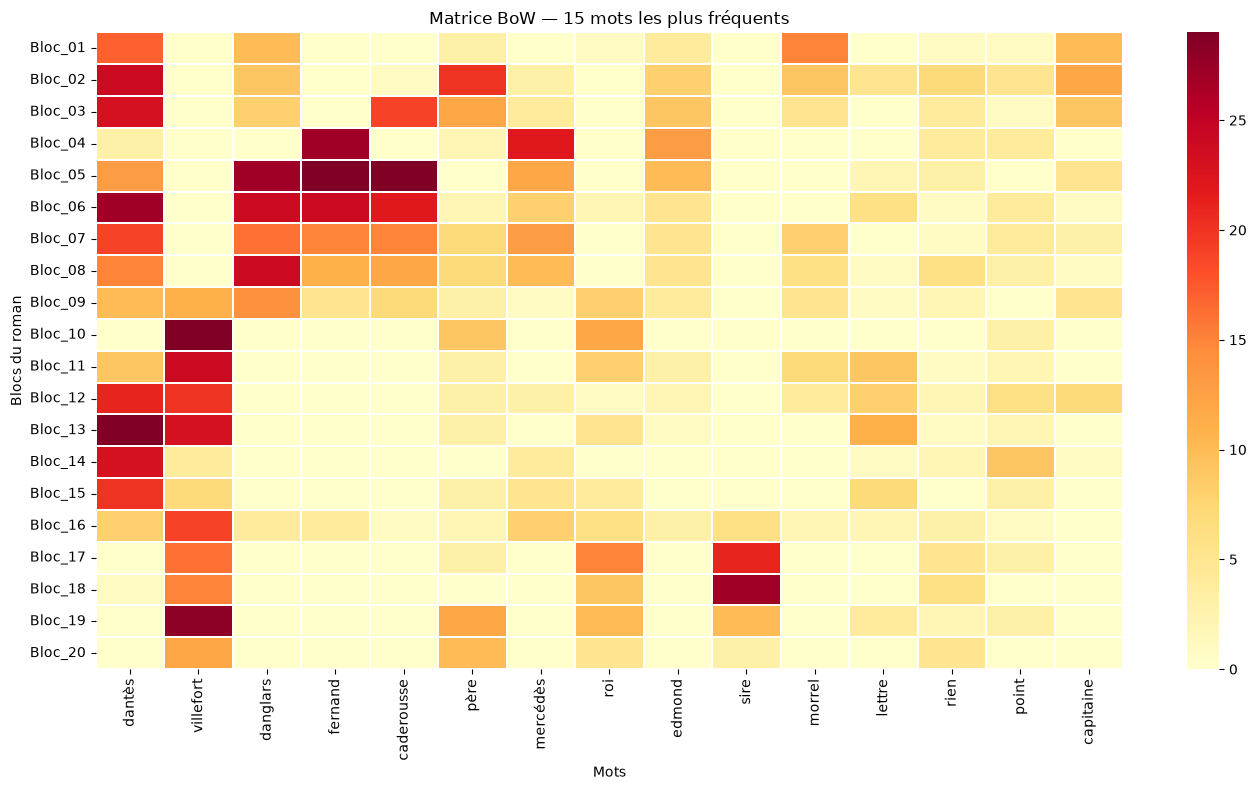

In [101]:
top_mots = bow_df.sum().sort_values(ascending=False).head(15).index

plt.figure(figsize=(14, 8))
sns.heatmap(bow_df[top_mots], cmap='YlOrRd', linewidths=0.3,
            xticklabels=True, yticklabels=True)
plt.title('Matrice BoW — 15 mots les plus fréquents')
plt.xlabel('Mots'); plt.ylabel('Blocs du roman')
plt.tight_layout()
plt.show()


# ✏️ Partie 10 — Travail demandé


### a) Dimensions de la matrice BoW.


In [102]:
print(f'Dimensions : {X_bow.shape[0]} blocs (lignes) × {X_bow.shape[1]} mots (colonnes)')


Dimensions : 20 blocs (lignes) × 300 mots (colonnes)


**Réponse a :** La matrice fait `n_blocs × n_mots` (ex. 20 × 300 avec `max_features=300`). Chaque ligne est un document (bloc), chaque colonne un mot du vocabulaire retenu.


### b) Que représente une ligne ? une colonne ? une cellule ?


**Réponse b :** Une **ligne** = un document (bloc de 2000 mots), représenté par son profil lexical. Une **colonne** = un mot du vocabulaire, et sa distribution à travers les blocs. Une **cellule** (i, j) = le nombre d'occurrences du mot j dans le bloc i.


### c) Bloc au vocabulaire le plus riche.


In [103]:
richesse_blocs = (bow_df > 0).sum(axis=1).sort_values(ascending=False)
print('Blocs par nombre de mots distincts :')
print(richesse_blocs.head(5))


Blocs par nombre de mots distincts :
Bloc_11    158
Bloc_08    158
Bloc_09    155
Bloc_16    154
Bloc_05    150
dtype: int64


**Réponse c :** Le bloc avec le plus de mots distincts (cellules non nulles) est le plus riche lexicalement — souvent un passage descriptif ou à dialogues variés plutôt qu'une scène répétitive.


### d) Blocs où 'dantès', 'danglars', 'faria' apparaissent le plus.


In [104]:
for perso in ['dantès', 'danglars', 'faria']:
    if perso in bow_df.columns:
        top = bow_df[perso].sort_values(ascending=False).head(3)
        print(f'{perso:<10}: {list(zip(top.index, top.values))}')
    else:
        print(f'{perso:<10}: absent du vocabulaire (min_df/max_features)')


dantès    : [('Bloc_13', np.int64(29)), ('Bloc_06', np.int64(27)), ('Bloc_02', np.int64(24))]
danglars  : [('Bloc_05', np.int64(27)), ('Bloc_06', np.int64(24)), ('Bloc_08', np.int64(24))]
faria     : absent du vocabulaire (min_df/max_features)


**Réponse d :** Les pics de chaque personnage correspondent aux parties du roman où il est actif : Faria culmine dans les blocs de la prison du château d'If, Danglars dans les intrigues financières/parisiennes, Dantès est présent partout (protagoniste). La matrice localise donc bien la structure narrative.


### e) Heatmap — commentaire.


**Réponse e :** La heatmap montre une distribution inégale : certains mots sont concentrés sur quelques blocs (personnages/lieux localisés, couleurs vives ponctuelles), d'autres répartis uniformément (mots de récit génériques). Les zones chaudes signalent les moments forts associés à un terme.


### f) Sparsité de la matrice.


In [105]:
zeros = (bow_df == 0).sum().sum()
total_cells = bow_df.shape[0] * bow_df.shape[1]
print(f'Cellules à 0 : {zeros:,} / {total_cells:,} = {zeros/total_cells*100:.1f}%')


Cellules à 0 : 3,213 / 6,000 = 53.5%


**Réponse f :** La matrice est creuse (souvent 60-80 % de zéros) : chaque bloc n'emploie qu'une fraction du vocabulaire global. Problème pour le ML : gaspillage mémoire, dimensions inutiles, et distances peu discriminantes en grande dimension (fléau de la dimensionnalité). D'où les formats sparse et les techniques de réduction (TF-IDF, embeddings).


## ❓ Partie 10 — Questions de réflexion

**Q1. Que représente une ligne / une colonne de la matrice Document-Terme ?**
Une ligne = un document (bloc) décrit par ses comptes de mots. Une colonne = un mot du vocabulaire et
sa présence à travers les documents.

**Q2. Pourquoi la matrice BoW est-elle très creuse ?**
Le vocabulaire global est grand, mais chaque document n'en utilise qu'une petite partie — la majorité
des cellules sont donc à zéro.

**Q3. Avantages du Bag of Words ?**
Simple, rapide, interprétable, et suffisant comme baseline pour la classification ou la recherche.

**Q4. Informations perdues avec le BoW ?**
L'ordre des mots, la syntaxe, le contexte, la négation et la polysémie. 'le chat mange la souris' et
'la souris mange le chat' ont le même vecteur BoW.


# 📈 Partie 11 — TF-IDF & Comparaison finale


### 11.2  Calcul TF-IDF


In [106]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vec = TfidfVectorizer(
    lowercase=True, stop_words=list(sw_custom),
    min_df=2, max_df=0.90, max_features=300,
    sublinear_tf=True, use_idf=True, smooth_idf=True,
)
X_tfidf = tfidf_vec.fit_transform(blocs)
vocab_tfidf = tfidf_vec.get_feature_names_out()

tfidf_df = pd.DataFrame(X_tfidf.toarray().round(4), index=noms_blocs, columns=vocab_tfidf)
print(f'Matrice TF-IDF : {X_tfidf.shape}')
print(tfidf_df.iloc[:3, :6])


Matrice TF-IDF : (20, 300)
         affaire   agent  ailleurs    aime     air    alla
Bloc_01   0.0516  0.0486       0.0  0.0000  0.0964  0.0486
Bloc_02   0.0000  0.0000       0.0  0.0575  0.0000  0.0510
Bloc_03   0.0000  0.0000       0.0  0.1276  0.0000  0.0539


sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['neuf', 'quelqu'] not in stop_words.
  warnings.warn(


### 11.3  Mots signatures par bloc


In [107]:
print(f'{"Bloc":<12} {"Top 6 mots (TF-IDF)"}')
print('-' * 65)
for i, bloc in enumerate(noms_blocs[:12]):
    top = tfidf_df.iloc[i].sort_values(ascending=False).head(6)
    print(f'{bloc:<12} {list(top.index)}')


Bloc         Top 6 mots (TF-IDF)
-----------------------------------------------------------------
Bloc_01      ['navire', 'armateur', 'bâtiment', 'morrel', 'leclère', 'marin']
Bloc_02      ['vieillard', 'armateur', 'leclère', 'capitaine', 'danglars', 'morrel']
Bloc_03      ['caderousse', 'argent', 'vieillard', 'danglars', 'capitaine', 'garçon']
Bloc_04      ['fernand', 'mercédès', 'ennemi', 'aime', 'catalan', 'larmes']
Bloc_05      ['fernand', 'caderousse', 'danglars', 'mercédès', 'vin', 'retournant']
Bloc_06      ['fernand', 'caderousse', 'danglars', 'papier', 'santé', 'moyen']
Bloc_07      ['fernand', 'caderousse', 'danglars', 'repas', 'mari', 'morrel']
Bloc_08      ['commissaire', 'danglars', 'fernand', 'caderousse', 'vieillard', 'douleur']
Bloc_09      ['napoléon', 'danglars', 'marquise', 'caderousse', 'fernand', 'villefort']
Bloc_10      ['marquise', 'renée', 'villefort', 'marquis', 'salvieux', 'napoléon']
Bloc_11      ['renée', 'marquise', 'villefort', 'procureur', 'morrel', 'ju

### 11.4  Similarité cosinus entre blocs


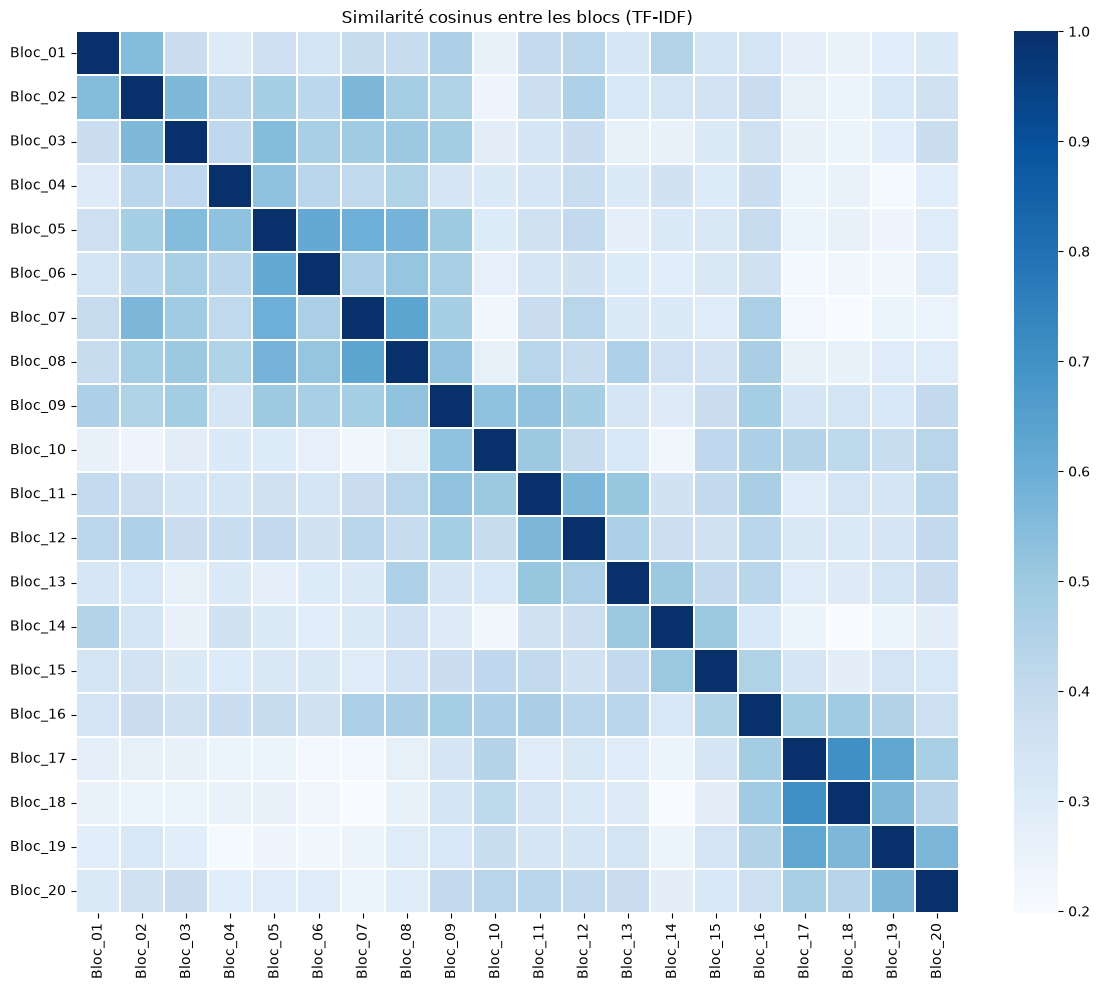

Blocs les plus similaires au Bloc_01 :
Bloc_02    0.552
Bloc_09    0.463
Bloc_14    0.448
Bloc_12    0.426
Bloc_11    0.402
Name: Bloc_01, dtype: float64


In [108]:
from sklearn.metrics.pairwise import cosine_similarity

sim_matrix = cosine_similarity(X_tfidf)
sim_df = pd.DataFrame(sim_matrix.round(3), index=noms_blocs, columns=noms_blocs)

plt.figure(figsize=(12, 10))
sns.heatmap(sim_df, cmap='Blues', xticklabels=True, yticklabels=True, linewidths=0.2)
plt.title('Similarité cosinus entre les blocs (TF-IDF)')
plt.tight_layout()
plt.show()

sim_bloc1 = sim_df['Bloc_01'].sort_values(ascending=False)[1:6]
print('Blocs les plus similaires au Bloc_01 :')
print(sim_bloc1)


### 11.5  Comparaison BoW vs TF-IDF


In [109]:
mot_test = 'dantès'
if mot_test in bow_df.columns:
    print(f'BoW    ({mot_test}) dans Bloc_01 : {bow_df.loc["Bloc_01", mot_test]}')
if mot_test in tfidf_df.columns:
    print(f'TF-IDF ({mot_test}) dans Bloc_01 : {tfidf_df.loc["Bloc_01", mot_test]:.4f}')

print('\nTop 10 par BoW    :', list(bow_df.sum().sort_values(ascending=False).head(10).index))
print('Top 10 par TF-IDF :', list(tfidf_df.sum().sort_values(ascending=False).head(10).index))


BoW    (dantès) dans Bloc_01 : 17
TF-IDF (dantès) dans Bloc_01 : 0.1296

Top 10 par BoW    : ['dantès', 'villefort', 'danglars', 'fernand', 'caderousse', 'père', 'mercédès', 'roi', 'edmond', 'sire']
Top 10 par TF-IDF : ['dantès', 'villefort', 'danglars', 'père', 'mercédès', 'fernand', 'roi', 'edmond', 'caderousse', 'morrel']


# ✏️ Partie 11 — Travail demandé


### a) Matrice TF-IDF, scores du Bloc_01.


In [110]:
print('Top 10 TF-IDF du Bloc_01 :')
print(tfidf_df.loc['Bloc_01'].sort_values(ascending=False).head(10))


Top 10 TF-IDF du Bloc_01 :
navire       0.2010
armateur     0.1912
bâtiment     0.1811
morrel       0.1803
leclère      0.1755
marin        0.1725
empereur     0.1640
danglars     0.1605
arrivé       0.1519
capitaine    0.1518
Name: Bloc_01, dtype: float64


**Réponse a :** Les scores TF-IDF du Bloc_01 valorisent les mots caractéristiques de ce passage (Marseille, Pharaon, Morrel...) plutôt que les mots fréquents partout — contrairement au simple comptage BoW.


### b) Top 5 TF-IDF par bloc — pertinents pour résumer ?


In [111]:
for i, bloc in enumerate(noms_blocs):
    top = tfidf_df.iloc[i].sort_values(ascending=False).head(5)
    print(f'{bloc:<10}: {list(top.index)}')


Bloc_01   : ['navire', 'armateur', 'bâtiment', 'morrel', 'leclère']
Bloc_02   : ['vieillard', 'armateur', 'leclère', 'capitaine', 'danglars']
Bloc_03   : ['caderousse', 'argent', 'vieillard', 'danglars', 'capitaine']
Bloc_04   : ['fernand', 'mercédès', 'ennemi', 'aime', 'catalan']
Bloc_05   : ['fernand', 'caderousse', 'danglars', 'mercédès', 'vin']
Bloc_06   : ['fernand', 'caderousse', 'danglars', 'papier', 'santé']
Bloc_07   : ['fernand', 'caderousse', 'danglars', 'repas', 'mari']
Bloc_08   : ['commissaire', 'danglars', 'fernand', 'caderousse', 'vieillard']
Bloc_09   : ['napoléon', 'danglars', 'marquise', 'caderousse', 'fernand']
Bloc_10   : ['marquise', 'renée', 'villefort', 'marquis', 'salvieux']
Bloc_11   : ['renée', 'marquise', 'villefort', 'procureur', 'morrel']
Bloc_12   : ['villefort', 'bonheur', 'juge', 'justice', 'dantès']
Bloc_13   : ['gendarmes', 'commissaire', 'villefort', 'juge', 'justice']
Bloc_14   : ['barque', 'geôlier', 'château', 'if', 'gendarmes']
Bloc_15   : ['geôl

**Réponse b :** Oui : les 5 mots au TF-IDF le plus élevé d'un bloc en résument bien le contenu spécifique (personnages, lieux, actions propres au passage). C'est une forme d'extraction de mots-clés.


### c) Similarité cosinus — blocs les plus proches.


In [112]:
import numpy as np
sim_no_diag = sim_matrix.copy()
np.fill_diagonal(sim_no_diag, 0)
i, j = np.unravel_index(sim_no_diag.argmax(), sim_no_diag.shape)
print(f'Paire la plus similaire : {noms_blocs[i]} <-> {noms_blocs[j]} = {sim_no_diag[i,j]:.3f}')


Paire la plus similaire : Bloc_17 <-> Bloc_18 = 0.705


**Réponse c :** Les blocs les plus proches partagent personnages et lieux (continuité narrative). Les blocs adjacents tendent à être plus similaires — la similarité cosinus capture la cohérence thématique du récit.


### d) Mini moteur de recherche TF-IDF.


In [113]:
requete = 'château if prison dantès'
requete_vec = tfidf_vec.transform([requete])
scores = cosine_similarity(requete_vec, X_tfidf)[0]
blocs_trouves = sorted(zip(noms_blocs, scores), key=lambda x: -x[1])[:3]
print('Requête :', requete)
print('Blocs les plus pertinents :')
for b, s in blocs_trouves:
    print(f'  {b} : {s:.3f}')


Requête : château if prison dantès
Blocs les plus pertinents :
  Bloc_14 : 0.361
  Bloc_15 : 0.219
  Bloc_01 : 0.211


**Réponse d :** La requête 'château if prison dantès' remonte les blocs de l'emprisonnement au château d'If — exactement les passages attendus. TF-IDF + cosinus = moteur de recherche fonctionnel : on projette la requête dans le même espace que les documents et on classe par proximité.


### e) BoW vs TF-IDF pour le Bloc_01 — le plus discriminant ?


In [114]:
print('BoW    top 8 Bloc_01 :', list(bow_df.loc['Bloc_01'].sort_values(ascending=False).head(8).index))
print('TF-IDF top 8 Bloc_01 :', list(tfidf_df.loc['Bloc_01'].sort_values(ascending=False).head(8).index))


BoW    top 8 Bloc_01 : ['dantès', 'morrel', 'armateur', 'île', 'capitaine', 'danglars', 'bâtiment', 'navire']
TF-IDF top 8 Bloc_01 : ['navire', 'armateur', 'bâtiment', 'morrel', 'leclère', 'marin', 'empereur', 'danglars']


**Réponse e :** TF-IDF est plus discriminant : il fait remonter les mots *spécifiques* au Bloc_01 alors que BoW privilégie les mots simplement fréquents (souvent communs à tous les blocs). Pour caractériser un document, TF-IDF est nettement supérieur.


## ❓ Partie 11 — Questions de réflexion

**Q1. Pourquoi TF-IDF est meilleur que BoW pour un moteur de recherche ?**
TF-IDF pondère chaque mot par sa rareté dans le corpus (IDF) : les mots discriminants pèsent plus,
les mots communs sont atténués. La pertinence d'une requête est donc bien mieux estimée qu'avec un
simple comptage.

**Q2. Que signifie un score TF-IDF élevé ?**
Le mot est fréquent dans ce document précis mais rare dans le reste du corpus : c'est un marqueur
caractéristique de ce document.

**Q3. Qu'est-ce que la similarité cosinus ? Valeur de similarité totale ?**
C'est le cosinus de l'angle entre deux vecteurs (indépendant de leur norme). Elle vaut 1 pour deux
documents identiques en direction (similarité totale) et 0 pour des documents sans mots communs
(orthogonaux).

**Q4. Quand TF-IDF donne-t-il de mauvais résultats ?**
Sur des documents très courts, des corpus trop homogènes (IDF peu informatif), en cas de synonymie
(mots de même sens comptés séparément) ou de polysémie. Il ignore aussi l'ordre et le contexte — d'où
les embeddings modernes (Word2Vec, BERT).


# 🏁 Partie 12 — Synthèse finale

**Q1. Décrivez les 10 étapes du pipeline NLP (objectif + entrée → sortie).**

1. **Chargement** — récupérer le texte brut. Entrée : URL → Sortie : chaîne Python.
2. **Nettoyage** — retirer le bruit (ponctuation, casse, chiffres). Texte brut → texte normalisé.
3. **Tokenisation** — découper en unités. Texte → liste de tokens.
4. **Analyse fréquentielle** — compter les mots. Tokens → fréquences.
5. **Stop words** — retirer les mots vides. Tokens → tokens filtrés.
6. **WordCloud** — visualiser les mots dominants. Tokens → image.
7. **Stemming** — réduire aux racines. Tokens → racines.
8. **Lemmatisation** — réduire aux lemmes valides + POS. Tokens → lemmes.
9. **BoW** — vectoriser par comptage. Documents → matrice Document-Terme.
10. **TF-IDF** — pondérer par rareté. Documents → matrice pondérée + similarités.

**Q2. Différence nettoyage vs tokenisation. Peut-on faire l'un sans l'autre ?**
Le nettoyage *transforme* le texte (minuscules, suppression du bruit) sans le découper ; la
tokenisation *segmente* en unités. On peut tokeniser sans nettoyer (mais on récupère ponctuation et
casse en tokens parasites) et nettoyer sans tokeniser (on garde une chaîne continue). Les deux sont
complémentaires : on nettoie d'abord, on tokenise ensuite.

**Q3. Stop words 'dit/répondit/monsieur' : justifié ici ? Et pour des tweets / avis clients ?**
Justifié pour ce roman très dialogué où ces mots sont omniprésents et sémantiquement vides. Pour des
tweets ou avis clients, ce ne sont PAS des stop words : 'dit'/'répondit' y sont rares et porteurs
d'information, et 'monsieur' peut signaler un ton ou une cible. Les stop words contextuels dépendent
toujours du corpus.

**Q4. Stemming vs lemmatisation — 3 exemples où la lemmatisation gagne.**
(1) 'chevaux' → stemming 'chev' / lemme 'cheval'. (2) 'allaient' → 'all' / 'aller'.
(3) 'meilleurs' → 'meilleur' tronqué / lemme 'bon'. La lemmatisation rend des mots valides et relie
les formes irrégulières, essentiel pour l'analyse littéraire.

**Q5. Pourquoi TF-IDF > BoW pour un moteur de recherche (exemple du roman).**
'château' est rare dans le corpus mais fréquent dans les blocs de prison : son IDF élevé lui donne un
TF-IDF fort *uniquement* là où il compte, donc une requête 'château if' remonte les bons passages. En
BoW, 'château' serait noyé parmi des mots fréquents partout et discriminerait mal.

**Q6. 3 questions auxquelles BoW/TF-IDF ne peuvent répondre + approche moderne.**
(1) « Dantès se venge-t-il par justice ou par cruauté ? » (sens, nuance morale). (2) « Telle réplique
est-elle ironique ? » (ironie). (3) « L'ordre des événements de l'évasion ? » (temporalité). BoW/TF-IDF
ignorent sens, contexte et ordre. Les modèles contextuels (Word2Vec pour la sémantique, surtout BERT/
CamemBERT et GPT) capturent le contexte et permettraient d'aborder ces questions.
